# Phase 4a: Unsupervised RFM Customer Segmentation

**Project**: Customer Intelligence Engine (RFM Segmentation + 90-Day CLV Regression)  
**Notebook**: `Notebooks/4_rfm_segmentation.ipynb` (Unsupervised Track Only)  
**Reusable Module**: `src/segmentation.py` + `tests/test_segmentation.py`

---

## Core Design Decisions (Locked & Interview-Defensible)
1. **Temporal Fitting Snapshot (`T_seg = 2011-09-10 00:00:00`, `lookback_days=None`)**:
   - We fit preprocessing and clustering on **full pre-cutoff history** across all registered customers who made at least one valid purchase before `2011-09-10`.
   - **Why `T_seg` instead of `2011-12-10` for model fitting?** Holding out the final 90 days `[2011-09-10, 2011-12-09)` lets us **externally validate** our discovered segments against actual unseen future spend and reactivation rate (`build_target` in Step 7). Because the pipeline fits strictly on transactions `< 2011-09-10`, zero future leakage enters the clusters.
2. **Core Clustering Feature Space (`recency_days`, `frequency`, `monetary`)**:
   - Keeping clustering strictly in 3D RFM space maximizes business interpretability for CRM teams and stakeholders. We run a later robustness check with `aov` added to verify structural stability.
3. **Production Deployment Simulation (`T_deploy = 2011-12-10 00:00:00`)**:
   - Once the single `sklearn.pipeline.Pipeline` is finalized and frozen on `T_seg`, we apply `.predict()` (transform + predict **only, no refit**) to `rfm_snapshot_2011-12-10.parquet` (`5,852` customers) to produce current CRM segments and audit 90-day customer migration.
4. **Human-in-the-Loop Segment Naming**:
   - Cluster IDs stay numeric (`0, 1, ...`) until full profiling (Step 6), after which business names and CRM actions are confirmed by the stakeholder.

## Strict Scope Guardrails
- **Allowed**: Full-history RFM snapshot construction, distributional diagnostics, RFM transformations & scaling inside one `sklearn` Pipeline, $K$-selection metrics, robustness checks, cluster profiling, external future-spend validation (post-hoc only), deployment scoring, visualization, and export.
- **Strictly Excluded**: Supervised CLV regression (Phase 4b), tuning or fitting clusters using future targets, or including `guest_transactions` / `admin_rows`.

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Locate repository root whether running from project root or Notebooks/
cwd = Path.cwd().resolve()
PROJECT_ROOT = cwd if (cwd / "src").exists() else cwd.parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.features import build_features

DATA_PROCESSED = PROJECT_ROOT / "data" / "processed"
FEATURES_DIR = DATA_PROCESSED / "features"

print(f"Project Root : {PROJECT_ROOT}")
print(f"Random State : {RANDOM_STATE}")
print(f"Sales Path   : {DATA_PROCESSED / 'sales_clean.parquet'}")
print(f"Returns Path : {DATA_PROCESSED / 'returns_clean.parquet'}")
print(f"Snapshot Path: {FEATURES_DIR / 'rfm_snapshot_2011-12-10.parquet'}")

Project Root : C:\Users\mosa\Desktop\Projects\Customer-Intelligence-Engine
Random State : 42
Sales Path   : data\processed\sales_clean.parquet
Returns Path : data\processed\returns_clean.parquet
Snapshot Path: data\processed\features\rfm_snapshot_2011-12-10.parquet


## Step 0: Build Full-History Snapshots (`T_seg` & `T_deploy`)

### Why Use Two Full-History Snapshots?
Unlike Phase 3's fixed `L = 270d` supervised windows (where equal lookbacks prevented cohort drift between `2010-09-10` and `2011-09-10`), **descriptive RFM segmentation wants every registered customer's complete observed relationship** (`lookback_days=None`) up to the segmentation date:
- **`T_seg = 2011-09-10 00:00:00`**: Historical snapshot containing every registered buyer who purchased at least once before Sep 10, 2011. Used to fit our single preprocessing + clustering `Pipeline` and evaluate external future spend over the unseen `[2011-09-10, 2011-12-09)` holiday quarter.
- **`T_deploy = 2011-12-10 00:00:00`** (`rfm_snapshot_2011-12-10.parquet`, `5,852` customers): Current-state snapshot covering all 24 months of clean history. Scored by the frozen pipeline via `.predict()` without refitting, mirroring real batch deployment.

In [2]:
T_SEG = pd.Timestamp("2011-09-10 00:00:00")
T_DEPLOY = pd.Timestamp("2011-12-10 00:00:00")

sales_clean = pd.read_parquet(DATA_PROCESSED / "sales_clean.parquet")
returns_clean = pd.read_parquet(DATA_PROCESSED / "returns_clean.parquet")

# 1. Build T_seg full-history snapshot (built-in build_features assertions verify < T_SEG)
rfm_seg_df = build_features(sales_clean, returns_clean, cutoff=T_SEG, lookback_days=None)

# 2. Load exported deployment snapshot at T_deploy = 2011-12-10 and confirm full parity
# Note: Parquet round-trip stores non-null Int64 Customer ID index as numpy int64
rfm_deploy_df = pd.read_parquet(FEATURES_DIR / "rfm_snapshot_2011-12-10.parquet")
rfm_deploy_rebuilt = build_features(sales_clean, returns_clean, cutoff=T_DEPLOY, lookback_days=None)
pd.testing.assert_frame_equal(rfm_deploy_df, rfm_deploy_rebuilt, check_index_type=False)

# 3. Explicit external temporal boundary verification
sales_pre_seg = sales_clean[sales_clean["InvoiceDate"] < T_SEG]
returns_pre_seg = returns_clean[returns_clean["InvoiceDate"] < T_SEG]
max_sale_seg = sales_pre_seg["InvoiceDate"].max()
max_ret_seg = returns_pre_seg["InvoiceDate"].max()

assert max_sale_seg < T_SEG, f"Leakage: max sale {max_sale_seg} >= {T_SEG}"
assert max_ret_seg < T_SEG, f"Leakage: max return {max_ret_seg} >= {T_SEG}"
assert sales_clean["InvoiceDate"].max() < T_DEPLOY, "Deployment max timestamp violated T_DEPLOY"

# 4. Customer cohort reconciliation between T_seg and T_deploy
ret_only_pre_seg = set(returns_pre_seg["Customer ID"].unique()) - set(sales_pre_seg["Customer ID"].unique())
seg_ids = set(rfm_seg_df.index)
deploy_ids = set(rfm_deploy_df.index)
shared_ids = seg_ids & deploy_ids
new_post_seg_ids = deploy_ids - seg_ids

# Check nulls in core RFM + validation/sensitivity columns
check_cols = ["recency_days", "frequency", "monetary", "aov", "return_rate", "is_single_invoice"]
assert rfm_seg_df[check_cols].isna().sum().sum() == 0, "Unexpected NaNs in core RFM columns (T_seg)!"
assert rfm_deploy_df[check_cols].isna().sum().sum() == 0, "Unexpected NaNs in core RFM columns (T_deploy)!"

print("=" * 72)
print("STEP 0 SUMMARY: FULL-HISTORY RFM SNAPSHOTS BUILT & VERIFIED")
print("=" * 72)
print(f"sales_clean range            : {sales_clean['InvoiceDate'].min()} --> {sales_clean['InvoiceDate'].max()}")
print(f"T_seg cutoff (fit cohort)    : {T_SEG} (exclusive)")
print(f"  Max sales InvoiceDate used : {max_sale_seg}  (< T_seg: {max_sale_seg < T_SEG})")
print(f"  Max return InvoiceDate used: {max_ret_seg}  (< T_seg: {max_ret_seg < T_SEG})")
print(f"  T_seg snapshot shape       : {rfm_seg_df.shape}")
print(f"  Excluded returns-only pre-T: {len(ret_only_pre_seg)} accounts")
print(f"T_deploy cutoff (live view)  : {T_DEPLOY}")
print(f"  T_deploy snapshot shape    : {rfm_deploy_df.shape} (100% parity with build_features)")
print(f"Cohort reconciliation        : {len(shared_ids):,} customers in BOTH | {len(new_post_seg_ids):,} new buyers after T_seg")
print(f"Nulls in {check_cols}     : 0 in both snapshots")

print("\n5 Sample Rows from rfm_seg_df (T_seg = 2011-09-10, Random Seed = 42):")
display_cols = ["recency_days", "frequency", "monetary", "aov", "tenure_days_in_window", "return_rate", "is_uk", "country"]
display(rfm_seg_df[display_cols].sample(5, random_state=RANDOM_STATE))

print("\n5 Sample Rows from rfm_deploy_df (T_deploy = 2011-12-10, Random Seed = 42):")
display(rfm_deploy_df[display_cols].sample(5, random_state=RANDOM_STATE))

STEP 0 SUMMARY: FULL-HISTORY RFM SNAPSHOTS BUILT & VERIFIED
sales_clean range            : 2009-12-01 07:45:00 --> 2011-12-09 12:50:00
T_seg cutoff (fit cohort)    : 2011-09-10 00:00:00 (exclusive)
  Max sales InvoiceDate used : 2011-09-09 15:53:00  (< T_seg: True)
  Max return InvoiceDate used: 2011-09-09 16:36:00  (< T_seg: True)
  T_seg snapshot shape       : (5256, 26)
  Excluded returns-only pre-T: 24 accounts
T_deploy cutoff (live view)  : 2011-12-10 00:00:00
  T_deploy snapshot shape    : (5852, 26) (100% parity with build_features)
Cohort reconciliation        : 5,256 customers in BOTH | 596 new buyers after T_seg
Nulls in ['recency_days', 'frequency', 'monetary', 'aov', 'return_rate', 'is_single_invoice']     : 0 in both snapshots

5 Sample Rows from rfm_seg_df (T_seg = 2011-09-10, Random Seed = 42):


,recency_days,frequency,monetary,aov,tenure_days_in_window,return_rate,is_uk,country
Customer ID,,,,,,,,
16089,295.422917,2,263.49,131.745,418.339583,0.0,1,United Kingdom
14384,409.588194,1,58.50,58.500,409.588194,0.0,1,United Kingdom
16491,322.345833,1,801.66,801.660,322.345833,0.5,1,United Kingdom
13016,32.375000,1,425.25,425.250,32.375000,0.0,1,United Kingdom
13171,208.405556,1,140.35,140.350,208.405556,0.0,1,United Kingdom



5 Sample Rows from rfm_deploy_df (T_deploy = 2011-12-10, Random Seed = 42):


,recency_days,frequency,monetary,aov,tenure_days_in_window,return_rate,is_uk,country
Customer ID,,,,,,,,
15684,547.214583,3,173.95,57.983333,735.324306,0.500000,1,United Kingdom
15271,7.409028,24,4528.54,188.689167,491.377083,0.076923,1,United Kingdom
15394,9.507639,11,5286.80,480.618182,724.204861,0.153846,1,United Kingdom
12369,413.449306,3,1511.15,503.716667,641.660417,0.000000,0,Austria
13443,448.478472,6,1269.37,211.561667,677.437500,0.142857,1,United Kingdom


## Step 1: RFM Distribution Diagnostics & Preprocessing Decision (STOP Point)

### Why Check Skewness & Outliers Before K-Means?
K-Means assigns customers to centroids by minimizing **squared Euclidean distance** ($\sum \|x_i - \mu_k\|^2$). This creates two severe failure modes on raw retail RFM data:
1. **Scale & Skewness Dominance**: Raw `monetary` spans from a few pounds to hundreds of thousands, while `frequency` ranges from `1` to `> 200` and `recency_days` from `0` to `~648`. Even after `StandardScaler`, extreme positive skewness pulls centroids outward and turns Euclidean distance into almost pure monetary difference.
2. **Whale Leverage**: A handful of ultra-high wholesale buyers sitting `20+` standard deviations away can hijack entire K-Means centroids—forcing clusters containing only 2–10 accounts unless transforms (`log1p` / `sqrt`) compress the tail sufficiently or outliers are explicitly capped/isolated.

Below we inspect exact raw vs. candidate transformed distributions (`sqrt`, `log1p`), top 1% monetary concentration, the top 10 biggest buyers, and the concrete quantitative impact of **Keep vs. Cap (99th pct) vs. Isolate** before locking our preprocessing specification.

STEP 1.1: RFM QUANTILES & SKEWNESS (RAW vs SQRT vs LOG1P)


,feature,min,q25,median,mean,q75,q95,q99,max,skew_raw,skew_sqrt,skew_log1p
0,recency_days,0.34,49.39,163.34,206.38,324.46,546.39,638.51,647.55,0.671,0.008,-1.021
1,frequency,1.00,1.00,3.00,5.71,6.00,19.00,42.00,284.00,10.487,2.961,1.058
2,monetary,1.55,316.56,776.15,2582.70,2060.91,8293.74,24372.91,456780.49,24.263,5.832,0.271


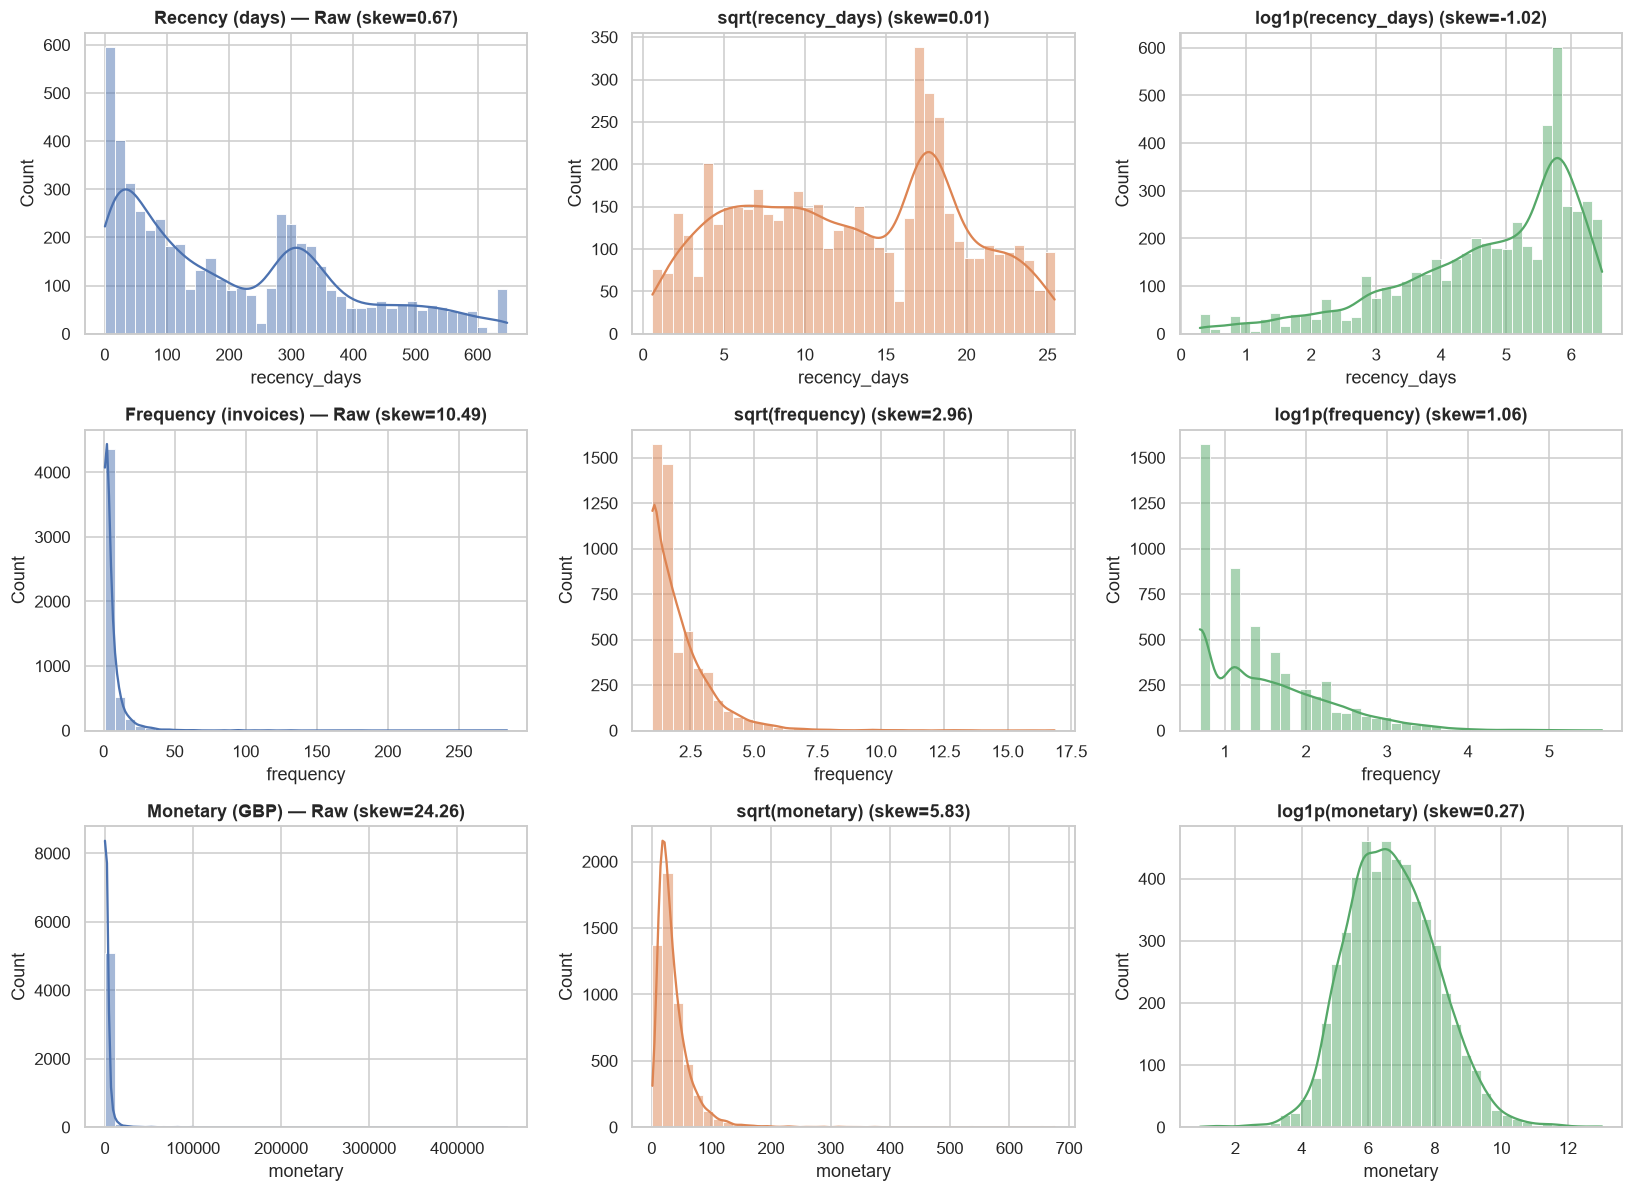


STEP 1.2: TOP 1% MONETARY CONCENTRATION & TOP 10 BIGGEST CUSTOMERS
Total historical spend (< T_seg) : £13,574,686.11 across 5,256 customers
Top 1% (53 customers) share   : 30.74% (threshold >= £24,372.91)
Top 10 customers share           : 16.04%
99th percentile cutoffs          : frequency=42.0 | monetary=£24,372.91


,recency_days,frequency,monetary,aov,return_rate,country,rev_share_pct
Customer ID,,,,,,,
18102,7.504861,112,456780.49,4078.397232,0.017544,United Kingdom,3.36
14646,1.522222,115,425343.12,3698.635826,0.057377,Netherlands,3.13
14156,2.333333,131,284748.59,2173.653359,0.196319,EIRE,2.10
14911,2.407639,284,212195.41,747.166937,0.202247,EIRE,1.56
13694,16.439583,132,176512.71,1337.217500,0.095890,United Kingdom,1.30
17511,2.513194,50,140446.24,2808.924800,0.285714,United Kingdom,1.03
17450,4.422222,28,136695.00,4881.964286,0.034483,United Kingdom,1.01
12415,8.422917,18,121206.72,6733.706667,0.142857,Australia,0.89
16684,42.366667,45,114372.71,2541.615778,0.166667,United Kingdom,0.84



STEP 1.3: TRANSFORM & WHALE HANDLING GEOMETRIC IMPACT COMPARISON


,strategy,n_rows,max_abs_z,pct_rows_z_gt_3,probe_k4_min_cluster_pct,probe_k4_silhouette,probe_k5_min_cluster_pct,probe_k5_silhouette
0,"A1: Keep all | sqrt(R) + log1p(F, M) [RECOMMENDED]",5256,5.31,1.24,21.88,0.3609,9.13,0.3421
1,"A2: Keep all | log1p(R, F, M)",5256,5.31,2.13,12.48,0.3799,10.27,0.3360
2,"B1: Cap F & M at q99 | sqrt(R) + log1p(F, M)",5256,4.33,0.25,22.60,0.3642,10.08,0.3419
3,"B2: Cap F & M at q99.5 | sqrt(R) + log1p(F, M)",5256,4.29,1.16,22.05,0.3629,9.84,0.3417
4,C: Isolate Top 1% monetary (cluster 99%),5203,4.43,0.73,21.85,0.3643,14.51,0.3360
5,"Baseline: Raw R, F, M (no log/sqrt) + StandardScaler",5256,37.73,1.27,0.08,0.5396,0.08,0.5472



5 Sample Rows (Raw R/F/M vs Candidate Transforms, Random Seed = 42):


,recency_days,frequency,monetary,sqrt_recency,log1p_recency,log1p_frequency,log1p_monetary
Customer ID,,,,,,,
16089,295.422917,2,263.49,17.188,5.692,1.099,5.578
14384,409.588194,1,58.50,20.238,6.018,0.693,4.086
16491,322.345833,1,801.66,17.954,5.779,0.693,6.688
13016,32.375000,1,425.25,5.690,3.508,0.693,6.055
13171,208.405556,1,140.35,14.436,5.344,0.693,4.951


In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

sns.set_theme(style="whitegrid")

RFM_COLS = ["recency_days", "frequency", "monetary"]
rfm_core = rfm_seg_df[RFM_COLS].copy()

# ---------------------------------------------------------------------
# 1.1 Raw vs Candidate Transform Skewness & Summary Quantiles
# ---------------------------------------------------------------------
diag_rows = []
for col in RFM_COLS:
    s = rfm_core[col]
    s_sqrt = np.sqrt(s)
    s_log1p = np.log1p(s)
    diag_rows.append({
        "feature": col,
        "min": round(float(s.min()), 2),
        "q25": round(float(s.quantile(0.25)), 2),
        "median": round(float(s.median()), 2),
        "mean": round(float(s.mean()), 2),
        "q75": round(float(s.quantile(0.75)), 2),
        "q95": round(float(s.quantile(0.95)), 2),
        "q99": round(float(s.quantile(0.99)), 2),
        "max": round(float(s.max()), 2),
        "skew_raw": round(float(skew(s)), 3),
        "skew_sqrt": round(float(skew(s_sqrt)), 3),
        "skew_log1p": round(float(skew(s_log1p)), 3),
    })

diag_df = pd.DataFrame(diag_rows)
print("=" * 72)
print("STEP 1.1: RFM QUANTILES & SKEWNESS (RAW vs SQRT vs LOG1P)")
print("=" * 72)
display(diag_df)

# ---------------------------------------------------------------------
# 1.2 Visualizations: Raw vs Candidate Transformed Distributions
# ---------------------------------------------------------------------
fig, axes = plt.subplots(3, 3, figsize=(15, 11))
plot_specs = [
    ("recency_days", "Recency (days)"),
    ("frequency", "Frequency (invoices)"),
    ("monetary", "Monetary (GBP)"),
]

for row_idx, (col, title_lbl) in enumerate(plot_specs):
    s = rfm_core[col]
    sns.histplot(s, bins=40, kde=True, ax=axes[row_idx, 0], color="#4c72b0")
    axes[row_idx, 0].set_title(f"{title_lbl} — Raw (skew={skew(s):.2f})", fontweight="bold")

    s_sqrt = np.sqrt(s)
    sns.histplot(s_sqrt, bins=40, kde=True, ax=axes[row_idx, 1], color="#dd8452")
    axes[row_idx, 1].set_title(f"sqrt({col}) (skew={skew(s_sqrt):.2f})", fontweight="bold")

    s_log = np.log1p(s)
    sns.histplot(s_log, bins=40, kde=True, ax=axes[row_idx, 2], color="#55a868")
    axes[row_idx, 2].set_title(f"log1p({col}) (skew={skew(s_log):.2f})", fontweight="bold")

plt.tight_layout()
plt.show()

# ---------------------------------------------------------------------
# 1.3 Top 1% Share of Monetary & Top 10 Biggest Customers
# ---------------------------------------------------------------------
total_rev_seg = rfm_seg_df["monetary"].sum()
n_top1pct = max(1, int(np.ceil(0.01 * len(rfm_seg_df))))
top_whales = rfm_seg_df.sort_values("monetary", ascending=False).copy()
top1pct_share = top_whales.iloc[:n_top1pct]["monetary"].sum() / total_rev_seg * 100
top10_share = top_whales.iloc[:10]["monetary"].sum() / total_rev_seg * 100
q99_m = float(rfm_seg_df["monetary"].quantile(0.99))
q99_f = float(rfm_seg_df["frequency"].quantile(0.99))

top10_view = top_whales[["recency_days", "frequency", "monetary", "aov", "return_rate", "country"]].head(10).copy()
top10_view["rev_share_pct"] = (top10_view["monetary"] / total_rev_seg * 100).round(2)

print("\n" + "=" * 72)
print("STEP 1.2: TOP 1% MONETARY CONCENTRATION & TOP 10 BIGGEST CUSTOMERS")
print("=" * 72)
print(f"Total historical spend (< T_seg) : £{total_rev_seg:,.2f} across {len(rfm_seg_df):,} customers")
print(f"Top 1% ({n_top1pct} customers) share   : {top1pct_share:.2f}% (threshold >= £{q99_m:,.2f})")
print(f"Top 10 customers share           : {top10_share:.2f}%")
print(f"99th percentile cutoffs          : frequency={q99_f:.1f} | monetary=£{q99_m:,.2f}")
display(top10_view)

# ---------------------------------------------------------------------
# 1.4 Transform & Whale-Treatment Impact Analysis
# Compare 4 concrete strategies at fixed probe K=4 & K=5 (seed=42)
# ---------------------------------------------------------------------
def apply_rfm_transform(df_in: pd.DataFrame, r_mode: str = "sqrt", cap_quantile: float | None = None) -> np.ndarray:
    sub = df_in[RFM_COLS].copy()
    if cap_quantile is not None:
        for c in ("frequency", "monetary"):
            upper = float(rfm_core[c].quantile(cap_quantile))
            sub[c] = np.minimum(sub[c], upper)
    r_tr = np.sqrt(sub["recency_days"]) if r_mode == "sqrt" else np.log1p(sub["recency_days"])
    f_tr = np.log1p(sub["frequency"])
    m_tr = np.log1p(sub["monetary"])
    return np.column_stack([r_tr, f_tr, m_tr])

strategies = {
    "A1: Keep all | sqrt(R) + log1p(F, M) [RECOMMENDED]": apply_rfm_transform(rfm_core, r_mode="sqrt", cap_quantile=None),
    "A2: Keep all | log1p(R, F, M)": apply_rfm_transform(rfm_core, r_mode="log1p", cap_quantile=None),
    "B1: Cap F & M at q99 | sqrt(R) + log1p(F, M)": apply_rfm_transform(rfm_core, r_mode="sqrt", cap_quantile=0.99),
    "B2: Cap F & M at q99.5 | sqrt(R) + log1p(F, M)": apply_rfm_transform(rfm_core, r_mode="sqrt", cap_quantile=0.995),
}

impact_rows = []
for name, X_tr in strategies.items():
    X_sc = StandardScaler().fit_transform(X_tr)
    max_abs_z = float(np.abs(X_sc).max())
    gt3_z_pct = float((np.abs(X_sc).max(axis=1) > 3.0).mean() * 100)

    km4 = KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE).fit(X_sc)
    min_sz4_pct = float(pd.Series(km4.labels_).value_counts(normalize=True).min() * 100)
    sil4 = float(silhouette_score(X_sc, km4.labels_))

    km5 = KMeans(n_clusters=5, n_init=20, random_state=RANDOM_STATE).fit(X_sc)
    min_sz5_pct = float(pd.Series(km5.labels_).value_counts(normalize=True).min() * 100)
    sil5 = float(silhouette_score(X_sc, km5.labels_))

    impact_rows.append({
        "strategy": name,
        "n_rows": len(X_sc),
        "max_abs_z": round(max_abs_z, 2),
        "pct_rows_z_gt_3": round(gt3_z_pct, 2),
        "probe_k4_min_cluster_pct": round(min_sz4_pct, 2),
        "probe_k4_silhouette": round(sil4, 4),
        "probe_k5_min_cluster_pct": round(min_sz5_pct, 2),
        "probe_k5_silhouette": round(sil5, 4),
    })

# Also evaluate Option C: Isolate top 1% monetary whales before clustering remaining 99%
mask_core99 = rfm_core["monetary"] < q99_m
X_iso = StandardScaler().fit_transform(apply_rfm_transform(rfm_core[mask_core99], r_mode="sqrt", cap_quantile=None))
km4_iso = KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE).fit(X_iso)
km5_iso = KMeans(n_clusters=5, n_init=20, random_state=RANDOM_STATE).fit(X_iso)
impact_rows.append({
    "strategy": "C: Isolate Top 1% monetary (cluster 99%)",
    "n_rows": int(mask_core99.sum()),
    "max_abs_z": round(float(np.abs(X_iso).max()), 2),
    "pct_rows_z_gt_3": round(float((np.abs(X_iso).max(axis=1) > 3.0).mean() * 100), 2),
    "probe_k4_min_cluster_pct": round(float(pd.Series(km4_iso.labels_).value_counts(normalize=True).min() * 100), 2),
    "probe_k4_silhouette": round(float(silhouette_score(X_iso, km4_iso.labels_)), 4),
    "probe_k5_min_cluster_pct": round(float(pd.Series(km5_iso.labels_).value_counts(normalize=True).min() * 100), 2),
    "probe_k5_silhouette": round(float(silhouette_score(X_iso, km5_iso.labels_)), 4),
})

# Compare against UNTRANSFORMED StandardScaler baseline to prove why transforms are mandatory
X_raw_sc = StandardScaler().fit_transform(rfm_core.to_numpy())
km4_raw = KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE).fit(X_raw_sc)
km5_raw = KMeans(n_clusters=5, n_init=20, random_state=RANDOM_STATE).fit(X_raw_sc)
impact_rows.append({
    "strategy": "Baseline: Raw R, F, M (no log/sqrt) + StandardScaler",
    "n_rows": len(X_raw_sc),
    "max_abs_z": round(float(np.abs(X_raw_sc).max()), 2),
    "pct_rows_z_gt_3": round(float((np.abs(X_raw_sc).max(axis=1) > 3.0).mean() * 100), 2),
    "probe_k4_min_cluster_pct": round(float(pd.Series(km4_raw.labels_).value_counts(normalize=True).min() * 100), 2),
    "probe_k4_silhouette": round(float(silhouette_score(X_raw_sc, km4_raw.labels_)), 4),
    "probe_k5_min_cluster_pct": round(float(pd.Series(km5_raw.labels_).value_counts(normalize=True).min() * 100), 2),
    "probe_k5_silhouette": round(float(silhouette_score(X_raw_sc, km5_raw.labels_)), 4),
})

impact_df = pd.DataFrame(impact_rows)
print("\n" + "=" * 72)
print("STEP 1.3: TRANSFORM & WHALE HANDLING GEOMETRIC IMPACT COMPARISON")
print("=" * 72)
display(impact_df)

# Diagnostic preview of 5 sample rows before & after proposed transforms
sample_tr = rfm_core.sample(5, random_state=RANDOM_STATE).copy()
sample_tr["sqrt_recency"] = np.sqrt(sample_tr["recency_days"]).round(3)
sample_tr["log1p_recency"] = np.log1p(sample_tr["recency_days"]).round(3)
sample_tr["log1p_frequency"] = np.log1p(sample_tr["frequency"]).round(3)
sample_tr["log1p_monetary"] = np.log1p(sample_tr["monetary"]).round(3)
print("\n5 Sample Rows (Raw R/F/M vs Candidate Transforms, Random Seed = 42):")
display(sample_tr)

### Locked Step 1 Decision (`A1`: `sqrt(R)` + `log1p(F, M)` + `StandardScaler`, Keep All Whales)
Based on Step 1 empirical diagnostics on `rfm_seg_df`:
- **`recency_days` -> `sqrt`**: Raw skewness (`0.671`) becomes `0.008` (whereas `log1p(R)` over-corrects to `-1.021`).
- **`frequency` & `monetary` -> `log1p`**: Skewness drops from `10.487` & `24.263` down to `1.058` & `0.271`.
- **Keep all whales uncapped**: After `log1p`, max `|z|` drops from `37.73` to `5.31`, forming balanced clusters (`>= 9.1%` min cluster size at `K=5`, `sil = 0.3421`) without arbitrary capping thresholds or breaking the single stateless `sklearn Pipeline`.

---

## Step 2: Baseline Rule-Based RFM Scoring (`src.segmentation.score_rfm_rules`)

### Why Build a Rule-Based Baseline First?
Before deploying K-Means clustering, an ML engineer must benchmark against the **standard business heuristic** (`1–5` RFM quintiles). Why?
1. **Fair Frequency Tie Handling**: Nearly **30%** (`1,575 / 5,256`) of customers have `frequency == 1`. Naive `pd.qcut(freq, 5)` crashes with `ValueError: Bin edges must be unique`, while `rank(method="first")` arbitrarily splits identical `frequency == 1` customers into `F=1` and `F=2` by row order. Instead, we use **average percentile ranking** (`rank(method="average", pct=True)`) binned at `[0.0, 0.2, 0.4, 0.6, 0.8, 1.0]`, ensuring **all customers with identical frequency receive the exact same F-score**.
2. **Accountability Benchmark**: Rule-based quintiles carve 3D RFM space with rigid, non-adaptive axis boxes and ignore massive continuous differences inside `M=5` (`£2.9k` to `£456k`). In Step 7, K-Means must beat this baseline at separating unseen future spend!

STEP 2 SUMMARY: RULE-BASED RFM SCORING BASELINE (T_seg = 2011-09-10)
Scored DataFrame shape : (5256, 10)
Distinct rule segments : 8

F_score Tie-Handling Verification (rank method='average', pct=True):


,customers,min_freq,max_freq
F_score,,,
1,1575,1,1
2,891,2,2
3,575,3,3
4,1170,4,7
5,1045,8,284



Rule-Based Baseline Segment Profiles (Sorted by Revenue Share %):


,customers,mean_R,median_R,mean_F,median_F,mean_M,median_M,total_revenue,mean_return_rate,cust_share_pct,rev_share_pct
rule_segment,,,,,,,,,,,
Champions,1232,36.03,29.41,15.05,10.0,7841.39,3519.84,9660597.80,0.16,23.44,71.17
Loyal Customers,631,127.34,126.29,6.45,5.0,2097.24,1220.38,1323357.16,0.14,12.01,9.75
At Risk (High Value),499,345.57,319.35,5.30,4.0,2354.35,1433.33,1174822.95,0.15,9.49,8.65
Hibernating / Lost,1603,406.48,367.36,1.46,1.0,361.47,306.18,579443.08,0.08,30.50,4.27
Potential Loyalists,439,49.40,47.33,2.46,2.0,832.12,635.19,365301.44,0.10,8.35,2.69
Need Attention,338,164.62,161.88,2.43,2.0,863.98,599.12,292026.69,0.12,6.43,2.15
About to Sleep,276,173.61,175.42,1.00,1.0,351.30,222.84,96958.06,0.07,5.25,0.71
Recent / New Customers,238,45.06,39.57,1.00,1.0,345.29,246.12,82178.92,0.06,4.53,0.61


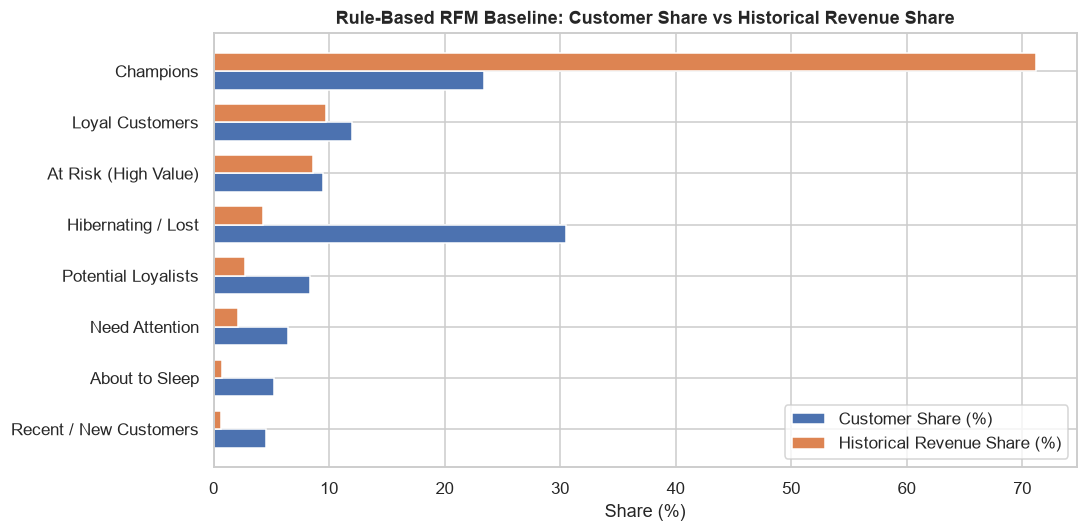


5 Sample Rows with Rule-Based RFM Scores (Random Seed = 42):


,recency_days,frequency,monetary,R_score,F_score,M_score,RFM_code,rule_segment
Customer ID,,,,,,,,
16089,295.422917,2,263.49,2,2,2,222,Hibernating / Lost
14384,409.588194,1,58.50,1,1,1,111,Hibernating / Lost
16491,322.345833,1,801.66,2,1,3,213,Hibernating / Lost
13016,32.375000,1,425.25,5,1,2,512,Recent / New Customers
13171,208.405556,1,140.35,3,1,1,311,About to Sleep


In [4]:
from src.segmentation import score_rfm_rules

rfm_rule_scores = score_rfm_rules(rfm_seg_df)
rfm_seg_with_rules = rfm_seg_df[["recency_days", "frequency", "monetary", "return_rate"]].join(rfm_rule_scores)

# 1. Verify tie-safe F_score monotonic intervals
f_tie_audit = (
    rfm_seg_with_rules.groupby("F_score")["frequency"]
    .agg(customers="count", min_freq="min", max_freq="max")
)
assert f_tie_audit.loc[1, "min_freq"] == 1 and f_tie_audit.loc[1, "max_freq"] == 1, (
    "All single-invoice customers should cleanly map to F_score == 1!"
)

# 2. Baseline segment profile summary
total_hist_rev = rfm_seg_with_rules["monetary"].sum()
rule_profile = (
    rfm_seg_with_rules.groupby("rule_segment")
    .agg(
        customers=("monetary", "count"),
        mean_R=("recency_days", "mean"),
        median_R=("recency_days", "median"),
        mean_F=("frequency", "mean"),
        median_F=("frequency", "median"),
        mean_M=("monetary", "mean"),
        median_M=("monetary", "median"),
        total_revenue=("monetary", "sum"),
        mean_return_rate=("return_rate", "mean"),
    )
    .assign(
        cust_share_pct=lambda d: (d["customers"] / len(rfm_seg_with_rules) * 100).round(2),
        rev_share_pct=lambda d: (d["total_revenue"] / total_hist_rev * 100).round(2),
    )
    .sort_values("rev_share_pct", ascending=False)
)

print("=" * 72)
print("STEP 2 SUMMARY: RULE-BASED RFM SCORING BASELINE (T_seg = 2011-09-10)")
print("=" * 72)
print(f"Scored DataFrame shape : {rfm_seg_with_rules.shape}")
print(f"Distinct rule segments : {rfm_seg_with_rules['rule_segment'].nunique()}")
print("\nF_score Tie-Handling Verification (rank method='average', pct=True):")
display(f_tie_audit)

print("\nRule-Based Baseline Segment Profiles (Sorted by Revenue Share %):")
display(rule_profile.round(2))

# Visualize customer share vs revenue share across rule-based segments
fig, ax = plt.subplots(figsize=(10, 5))
plot_df = rule_profile[["cust_share_pct", "rev_share_pct"]].sort_values("rev_share_pct", ascending=True)
y_pos = np.arange(len(plot_df))
height = 0.36
ax.barh(y_pos - height / 2, plot_df["cust_share_pct"], height, label="Customer Share (%)", color="#4c72b0")
ax.barh(y_pos + height / 2, plot_df["rev_share_pct"], height, label="Historical Revenue Share (%)", color="#dd8452")
ax.set_yticks(y_pos)
ax.set_yticklabels(plot_df.index)
ax.set_xlabel("Share (%)")
ax.set_title("Rule-Based RFM Baseline: Customer Share vs Historical Revenue Share", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.show()

print("\n5 Sample Rows with Rule-Based RFM Scores (Random Seed = 42):")
sample_rule_cols = [
    "recency_days", "frequency", "monetary", "R_score", "F_score", "M_score", "RFM_code", "rule_segment"
]
display(rfm_seg_with_rules[sample_rule_cols].sample(5, random_state=RANDOM_STATE))

## Step 3: Build & Unit-Test the Unified `sklearn` Pipeline

### Why Encapsulate Preprocessing + Clustering in ONE `sklearn` `Pipeline`?
In Step 8, we must score the unseen `2011-12-10` deployment snapshot using the **exact scaler mean and variance fit on `T_seg` (`2011-09-10`)**—never refitting `StandardScaler` on the new data. Wrapping:
1. `FunctionTransformer(transform_rfm_features)` (`sqrt(recency_days)`, `log1p(frequency)`, `log1p(monetary)`) — implemented as a top-level named function in `src/segmentation.py` so `joblib` can pickle/unpickle cleanly across environments,
2. `StandardScaler()` — centers and scales transformed features to zero mean and unit variance,
3. `KMeans(n_init=20, random_state=42)` — fits cluster centroids cleanly inside one single `.fit()` / `.predict()` API.

Below we unit-test the transform math on a tiny toy DataFrame and inspect the fitted preprocessor matrix (`X_seg_scaled`) before searching for optimal $K$ in Step 4.

In [5]:
from src.segmentation import (
    RFM_COLUMNS,
    build_rfm_pipeline,
    build_rfm_preprocessor,
    transform_rfm_features,
)

# 1. Toy DataFrame unit test inside notebook verifying exact transform & scaler math
toy_df = pd.DataFrame({
    "recency_days": [0.0, 4.0, 9.0, 16.0],
    "frequency": [1, 3, 7, 15],
    "monetary": [np.e - 1.0, np.e**2 - 1.0, np.e**3 - 1.0, np.e**4 - 1.0],
    "extra_col": ["ignore_me"] * 4,
})
toy_tr = transform_rfm_features(toy_df, recency_transform="sqrt")
assert toy_tr.shape == (4, 3)
np.testing.assert_allclose(toy_tr[:, 0], [0.0, 2.0, 3.0, 4.0], rtol=1e-7)
np.testing.assert_allclose(toy_tr[:, 1], np.log1p([1, 3, 7, 15]), rtol=1e-7)
np.testing.assert_allclose(toy_tr[:, 2], [1.0, 2.0, 3.0, 4.0], rtol=1e-7)

toy_pipe = build_rfm_pipeline(n_clusters=2, n_init=20, random_state=RANDOM_STATE)
toy_labels = toy_pipe.fit_predict(toy_df)
assert set(toy_labels) == {0, 1}
print("UNIT TEST PASSED: Toy DataFrame transform, StandardScaler, and full 3-step Pipeline verified!")

# 2. Fit preprocessing steps on T_seg snapshot (5,256 x 3) and inspect standardized space
rfm_preprocessor = build_rfm_preprocessor(feature_cols=RFM_COLUMNS, recency_transform="sqrt")
X_seg_scaled = rfm_preprocessor.fit_transform(rfm_seg_df)

scaled_cols = [f"z_{c}" for c in RFM_COLUMNS]
X_seg_scaled_df = pd.DataFrame(X_seg_scaled, index=rfm_seg_df.index, columns=scaled_cols)

assert X_seg_scaled_df.shape == (len(rfm_seg_df), 3)
np.testing.assert_allclose(X_seg_scaled.mean(axis=0), 0.0, atol=1e-12)
np.testing.assert_allclose(X_seg_scaled.std(axis=0, ddof=0), 1.0, atol=1e-12)

# Verify full 3-step sklearn Pipeline instantiation contract
probe_pipeline = build_rfm_pipeline(n_clusters=4, n_init=20, random_state=RANDOM_STATE)

print("\n" + "=" * 72)
print("STEP 3 SUMMARY: UNIFIED SKLEARN PIPELINE READY")
print("=" * 72)
print(f"Pipeline steps            : {[name for name, _ in probe_pipeline.steps]}")
print(f"Transformed matrix shape  : {X_seg_scaled_df.shape}")
print("\nStandardized Feature Summary (fit on T_seg = 2011-09-10):")
display(X_seg_scaled_df.describe().loc[["mean", "std", "min", "50%", "max"]].round(4))

print("\n5 Sample Rows: Raw RFM vs Pipeline-Standardized Z-Scores (Random Seed = 42):")
sample_pipe_view = rfm_seg_df[RFM_COLUMNS].join(X_seg_scaled_df).sample(5, random_state=RANDOM_STATE)
display(sample_pipe_view.round(4))

UNIT TEST PASSED: Toy DataFrame transform, StandardScaler, and full 3-step Pipeline verified!

STEP 3 SUMMARY: UNIFIED SKLEARN PIPELINE READY
Pipeline steps            : ['transform', 'scaler', 'kmeans']
Transformed matrix shape  : (5256, 3)

Standardized Feature Summary (fit on T_seg = 2011-09-10):


,z_recency_days,z_frequency,z_monetary
mean,0.0000,0.0000,0.0000
std,1.0001,1.0001,1.0001
min,-1.8334,-1.0182,-4.2536
50%,0.0057,-0.1342,-0.0511
max,1.9152,5.3068,4.6340



5 Sample Rows: Raw RFM vs Pipeline-Standardized Z-Scores (Random Seed = 42):


,recency_days,frequency,monetary,z_recency_days,z_frequency,z_monetary
Customer ID,,,,,,
16089,295.4229,2,263.49,0.6701,-0.5011,-0.8430
14384,409.5882,1,58.50,1.1300,-1.0182,-1.9392
16491,322.3458,1,801.66,0.7856,-1.0182,-0.0274
13016,32.3750,1,425.25,-1.0633,-1.0182,-0.4924
13171,208.4056,1,140.35,0.2553,-1.0182,-1.3034


## Step 4: Multi-Metric $K$-Selection Sweep (`K = 2..10`) *(STOP Point)*

### Why Elbow Alone Is Never Enough
In-sample **Inertia** (within-cluster sum of squared distances) decreases monotonically as $K$ grows until every point is its own cluster ($K = N \Rightarrow \text{inertia} = 0$). On smooth, continuous retail RFM clouds, inertia curves bend gently rather than forming a sharp visual corner—making the "elbow" subjective and easy to cherry-pick.

To select a robust, business-usable $K$, we triangulate **five orthogonal criteria** across `K = 2..10`:
1. **Inertia (Elbow)**: Marginal reduction in within-cluster compactness.
2. **Silhouette Score** *(higher is better)*: Measures both cohesion within clusters and separation from the nearest neighboring cluster.
3. **Davies-Bouldin Index** *(lower is better)*: Ratio of within-cluster scatter to between-cluster centroid separation.
4. **Calinski-Harabasz Index** *(higher is better)*: Ratio of between-cluster dispersion to within-cluster dispersion.
5. **Bootstrap Stability (Mean ARI across 20 bootstrap resamples)**: Measures whether cluster boundaries stay reproducible when sampling perturbations occur—critical so CRM segments do not flip randomly between weeks.
6. **Minimum Cluster Size (`>= 3%` Guardrail)**: Flags tiny niche clusters under 3% of accounts (`< 158` customers) that lack statistical power or CRM operational value.

STEP 4.1: K-SELECTION VALIDITY & BOOTSTRAP STABILITY METRICS (K=2..10)


,K,inertia,silhouette,davies_bouldin,calinski_harabasz,stability_ari_mean,stability_ari_std,min_cluster_size,min_cluster_pct,max_cluster_pct,flag_lt_3pct
0,2,7589.8,0.4402,0.8507,5661.4,0.9813,0.0134,2062,39.23,60.77,False
1,3,5476.8,0.3529,1.0096,4935.3,0.9498,0.0274,1148,21.84,39.21,False
2,4,4332.5,0.3609,0.9605,4621.0,0.8939,0.0730,1150,21.88,32.02,False
3,5,3508.4,0.3421,0.9148,4587.2,0.9515,0.0214,480,9.13,26.77,False
4,6,3124.0,0.3200,0.9757,4249.7,0.8857,0.1066,327,6.22,24.89,False
5,7,2775.9,0.3029,0.9786,4094.6,0.8936,0.0699,303,5.76,19.73,False
6,8,2551.3,0.2885,1.0190,3883.8,0.8562,0.1543,293,5.57,17.88,False
7,9,2364.5,0.2853,1.0153,3718.1,0.8107,0.1427,203,3.86,15.77,False
8,10,2204.7,0.2773,1.0132,3586.0,0.6066,0.1320,200,3.81,14.46,False



Exact Cluster Sizes per K (descending counts):
  K= 2 | min=39.23% | sizes: 3194 (60.8%) / 2062 (39.2%)
  K= 3 | min=21.84% | sizes: 2061 (39.2%) / 2047 (38.9%) / 1148 (21.8%)
  K= 4 | min=21.88% | sizes: 1683 (32.0%) / 1246 (23.7%) / 1177 (22.4%) / 1150 (21.9%)
  K= 5 | min= 9.13% | sizes: 1407 (26.8%) / 1217 (23.2%) / 1128 (21.5%) / 1024 (19.5%) / 480 (9.1%)
  K= 6 | min= 6.22% | sizes: 1308 (24.9%) / 1120 (21.3%) / 885 (16.8%) / 872 (16.6%) / 744 (14.2%) / 327 (6.2%)
  K= 7 | min= 5.76% | sizes: 1037 (19.7%) / 1011 (19.2%) / 860 (16.4%) / 785 (14.9%) / 652 (12.4%) / 608 (11.6%) / 303 (5.8%)
  K= 8 | min= 5.57% | sizes: 940 (17.9%) / 787 (15.0%) / 753 (14.3%) / 732 (13.9%) / 629 (12.0%) / 604 (11.5%) / 518 (9.9%) / 293 (5.6%)
  K= 9 | min= 3.86% | sizes: 829 (15.8%) / 747 (14.2%) / 672 (12.8%) / 650 (12.4%) / 605 (11.5%) / 583 (11.1%) / 524 (10.0%) / 443 (8.4%) / 203 (3.9%)
  K=10 | min= 3.81% | sizes: 760 (14.5%) / 606 (11.5%) / 601 (11.4%) / 579 (11.0%) / 565 (10.7%) / 561 (10.7%)

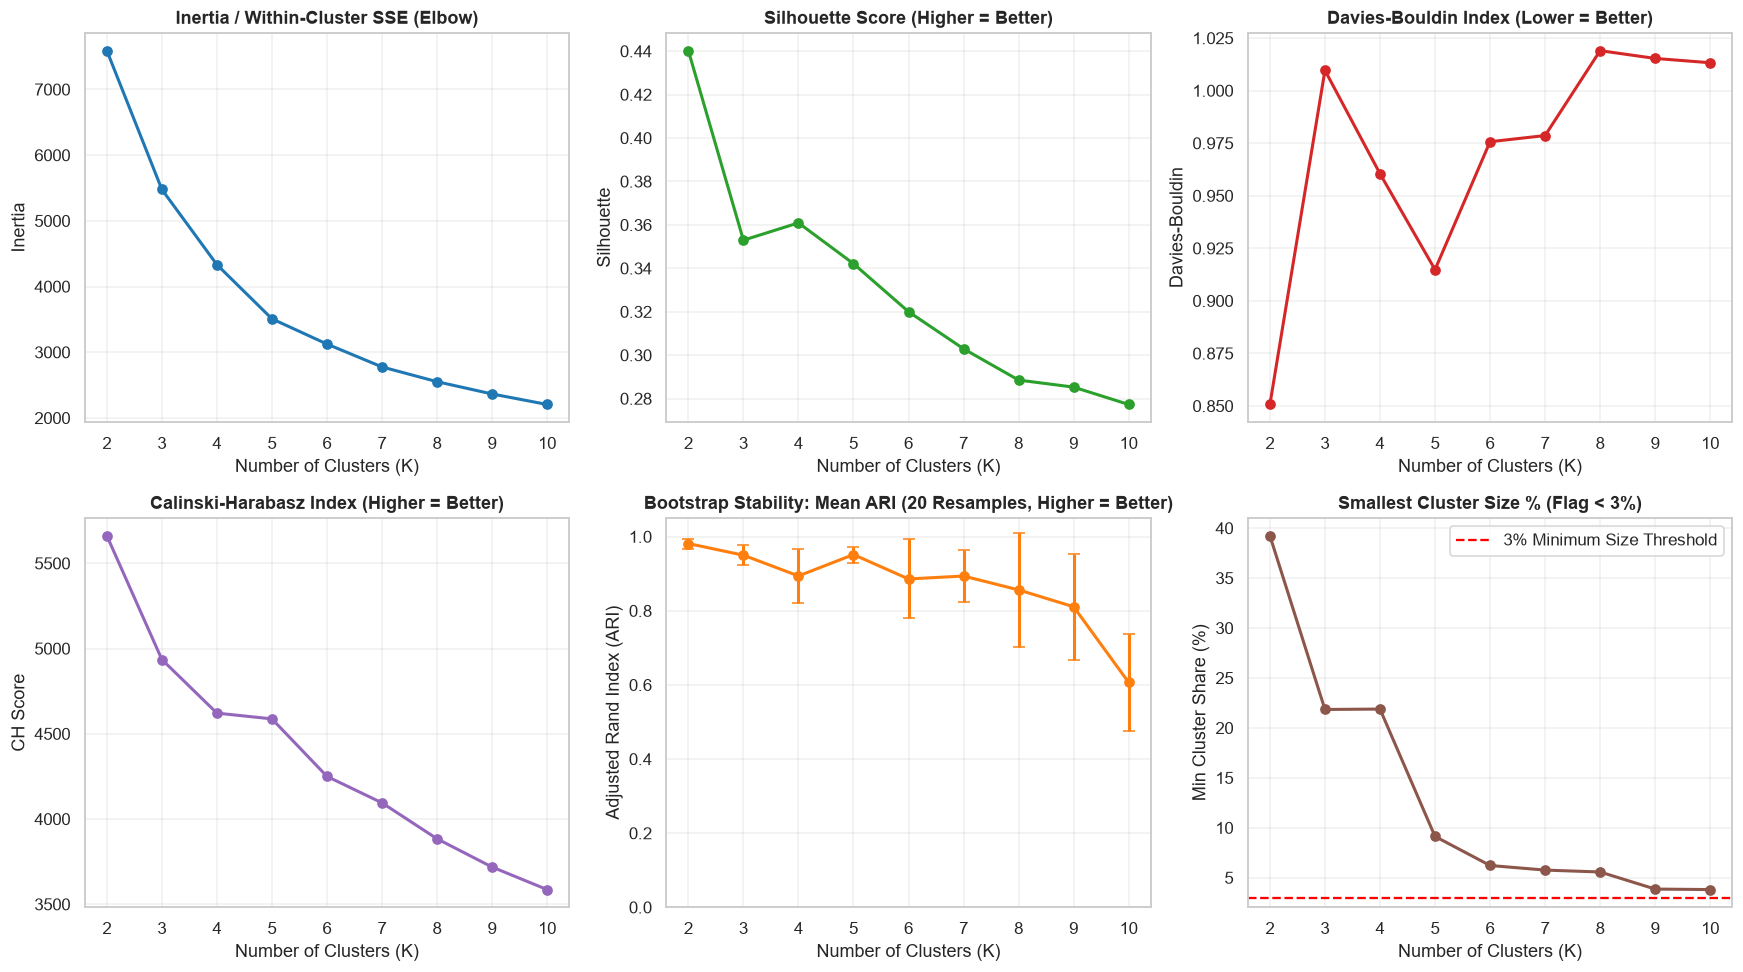


STEP 4.2: QUICK CLUSTER MEDIAN RFM PREVIEW FOR CANDIDATE K IN {3, 4, 5, 6}

--- Candidate K = 3 ---


,count,share_pct,med_R,med_F,med_M
cluster,,,,,
0,1148,21.8,29.5,11.0,4417.9
2,2047,38.9,98.4,3.0,953.2
1,2061,39.2,343.3,1.0,298.5



--- Candidate K = 4 ---


,count,share_pct,med_R,med_F,med_M
cluster,,,,,
1,1150,21.9,29.4,11.0,4291.7
0,1246,23.7,268.4,4.0,1261.3
3,1177,22.4,57.3,2.0,591.8
2,1683,32.0,352.6,1.0,257.4



--- Candidate K = 5 ---


,count,share_pct,med_R,med_F,med_M
cluster,,,,,
1,480,9.1,16.6,19.0,7850.6
4,1217,23.2,54.4,7.0,2251.6
0,1128,21.5,296.4,3.0,985.8
3,1024,19.5,73.0,2.0,441.2
2,1407,26.8,371.6,1.0,231.9



--- Candidate K = 6 ---


,count,share_pct,med_R,med_F,med_M
cluster,,,,,
4,327,6.2,15.4,24.0,9972.6
1,872,16.6,45.5,9.0,3333.7
3,885,16.8,58.5,4.0,1084.6
2,1120,21.3,295.5,3.0,983.9
0,744,14.2,103.4,1.0,298.2
5,1308,24.9,393.3,1.0,236.1



5 Sample Rows with Provisional Cluster Labels for K = 3, 4, 5, 6 (Random Seed = 42):


,recency_days,frequency,monetary,K3_cluster,K4_cluster,K5_cluster,K6_cluster
Customer ID,,,,,,,
16089,295.42,2,263.49,1,2,2,5
14384,409.59,1,58.50,1,2,2,5
16491,322.35,1,801.66,1,2,0,2
13016,32.38,1,425.25,2,3,3,0
13171,208.41,1,140.35,1,2,2,0


In [6]:
from src.segmentation import evaluate_kmeans_k_range

k_metrics_df, k_labels_map = evaluate_kmeans_k_range(
    X_seg_scaled,
    k_values=range(2, 11),
    n_init=20,
    n_resamples=20,
    random_state=RANDOM_STATE,
)

print("=" * 72)
print("STEP 4.1: K-SELECTION VALIDITY & BOOTSTRAP STABILITY METRICS (K=2..10)")
print("=" * 72)
display(
    k_metrics_df.drop(columns=["cluster_sizes"]).round({
        "inertia": 1,
        "silhouette": 4,
        "davies_bouldin": 4,
        "calinski_harabasz": 1,
        "stability_ari_mean": 4,
        "stability_ari_std": 4,
    })
)

print("\nExact Cluster Sizes per K (descending counts):")
for _, row in k_metrics_df.iterrows():
    flag_txt = " [FLAG < 3%]" if row["flag_lt_3pct"] else ""
    print(f"  K={int(row['K']):2d} | min={row['min_cluster_pct']:5.2f}% | sizes: {row['cluster_sizes']}{flag_txt}")

# Plot all 6 metrics together in a 2x3 dashboard
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
ks = k_metrics_df["K"]

axes[0, 0].plot(ks, k_metrics_df["inertia"], marker="o", linewidth=2, color="#1f77b4")
axes[0, 0].set_title("Inertia / Within-Cluster SSE (Elbow)", fontweight="bold")
axes[0, 0].set_ylabel("Inertia")

axes[0, 1].plot(ks, k_metrics_df["silhouette"], marker="o", linewidth=2, color="#2ca02c")
axes[0, 1].set_title("Silhouette Score (Higher = Better)", fontweight="bold")
axes[0, 1].set_ylabel("Silhouette")

axes[0, 2].plot(ks, k_metrics_df["davies_bouldin"], marker="o", linewidth=2, color="#d62728")
axes[0, 2].set_title("Davies-Bouldin Index (Lower = Better)", fontweight="bold")
axes[0, 2].set_ylabel("Davies-Bouldin")

axes[1, 0].plot(ks, k_metrics_df["calinski_harabasz"], marker="o", linewidth=2, color="#9467bd")
axes[1, 0].set_title("Calinski-Harabasz Index (Higher = Better)", fontweight="bold")
axes[1, 0].set_ylabel("CH Score")

axes[1, 1].errorbar(
    ks,
    k_metrics_df["stability_ari_mean"],
    yerr=k_metrics_df["stability_ari_std"],
    marker="o",
    linewidth=2,
    capsize=4,
    color="#ff7f0e",
)
axes[1, 1].set_title("Bootstrap Stability: Mean ARI (20 Resamples, Higher = Better)", fontweight="bold")
axes[1, 1].set_ylabel("Adjusted Rand Index (ARI)")
axes[1, 1].set_ylim(0, 1.05)

axes[1, 2].plot(ks, k_metrics_df["min_cluster_pct"], marker="o", linewidth=2, color="#8c564b")
axes[1, 2].axhline(3.0, color="red", linestyle="--", linewidth=1.5, label="3% Minimum Size Threshold")
axes[1, 2].set_title("Smallest Cluster Size % (Flag < 3%)", fontweight="bold")
axes[1, 2].set_ylabel("Min Cluster Share (%)")
axes[1, 2].legend()

for ax in axes.flat:
    ax.set_xticks(ks)
    ax.set_xlabel("Number of Clusters (K)")
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# Show median RFM teaser for shortlist inspection across K in [3, 4, 5, 6]
print("\n" + "=" * 72)
print("STEP 4.2: QUICK CLUSTER MEDIAN RFM PREVIEW FOR CANDIDATE K IN {3, 4, 5, 6}")
print("=" * 72)
for k_cand in (3, 4, 5, 6):
    temp = rfm_seg_df[["recency_days", "frequency", "monetary"]].copy()
    temp["cluster"] = k_labels_map[k_cand]
    prof = temp.groupby("cluster").agg(
        count=("monetary", "count"),
        share_pct=("monetary", lambda s: round(len(s) / len(temp) * 100, 1)),
        med_R=("recency_days", "median"),
        med_F=("frequency", "median"),
        med_M=("monetary", "median"),
    ).sort_values("med_M", ascending=False)
    print(f"\n--- Candidate K = {k_cand} ---")
    display(prof.round(1))

# 5 sample rows showing assignments across candidate K values
sample_k_df = rfm_seg_df[RFM_COLUMNS].copy()
for k_cand in (3, 4, 5, 6):
    sample_k_df[f"K{k_cand}_cluster"] = k_labels_map[k_cand]

print("\n5 Sample Rows with Provisional Cluster Labels for K = 3, 4, 5, 6 (Random Seed = 42):")
display(sample_k_df.sample(5, random_state=RANDOM_STATE).round(2))

### Locked Step 4 Decision: `K = 5`
We lock **`CHOSEN_K = 5`** based on converging empirical evidence:
- **Lowest Davies-Bouldin Index among all actionable solutions (`0.9148`)**, outperforming `K=3` (`1.0096`), `K=4` (`0.9605`), and `K=6` (`0.9757`).
- **Peak bootstrap stability (`ARI = 0.9515 ± 0.0214`)**, sharply more reproducible than `K=4` (`0.8939 ± 0.0730`) and `K=6` (`0.8857 ± 0.1066`).
- **Balanced segment sizes (`min = 9.13%` / `480` customers)**—zero small-cluster warnings (`< 3%`).

---

## Step 5: Structural Robustness & Feature Sensitivity Check (`K = 5`)

### Why Compare Across Algorithms & Add `aov`?
Any clustering partition should be tested for sensitivity to algorithmic bias and feature specification:
1. **Ward Hierarchical Clustering (`linkage="ward"`)**: Deterministic bottom-up variance-minimization tree; high ARI against K-Means confirms boundaries are not random local-minimum artifacts.
2. **Gaussian Mixture Model (`GMM`, `covariance_type="full"`)**: Fits elliptical clusters with soft covariance matrices instead of equal spherical radii—revealing whether dense one-time buyers (`frequency == 1` zero-variance ridge!) or wholesale tails follow elliptical density contours differently.
3. **`aov` Sensitivity (`RFM + log1p(aov)`)**: Since `aov = monetary / frequency`, adding `aov` double-weights basket ticket size relative to order cadence—testing whether high-ticket infrequent buyers reorganize into separate segments.

STEP 5 SUMMARY: ROBUSTNESS & AOV SENSITIVITY CHECK (K = 5)


,method,n_clusters,ari_vs_kmeans,nmi_vs_kmeans,silhouette,min_cluster_pct
0,KMeans (3D RFM Baseline),5,1.0000,1.0000,0.3421,9.13
1,"Gaussian Mixture (Full Cov, 3D RFM)",5,0.3888,0.4760,0.1551,11.02
2,Ward Hierarchical (3D RFM),5,0.5347,0.6331,0.2736,8.81
3,KMeans Sensitivity (RFM + log1p(aov)),5,0.3089,0.4505,0.2698,13.98



Cluster Size Distributions Across Methods:
  KMeans (3D RFM Baseline)               | min= 9.13% | 1407 (26.8%) / 1217 (23.2%) / 1128 (21.5%) / 1024 (19.5%) / 480 (9.1%)
  Gaussian Mixture (Full Cov, 3D RFM)    | min=11.02% | 1575 (30.0%) / 1524 (29.0%) / 891 (17.0%) / 687 (13.1%) / 579 (11.0%)
  Ward Hierarchical (3D RFM)             | min= 8.81% | 1708 (32.5%) / 1253 (23.8%) / 923 (17.6%) / 909 (17.3%) / 463 (8.8%)
  KMeans Sensitivity (RFM + log1p(aov))  | min=13.98% | 1369 (26.0%) / 1307 (24.9%) / 961 (18.3%) / 884 (16.8%) / 735 (14.0%)


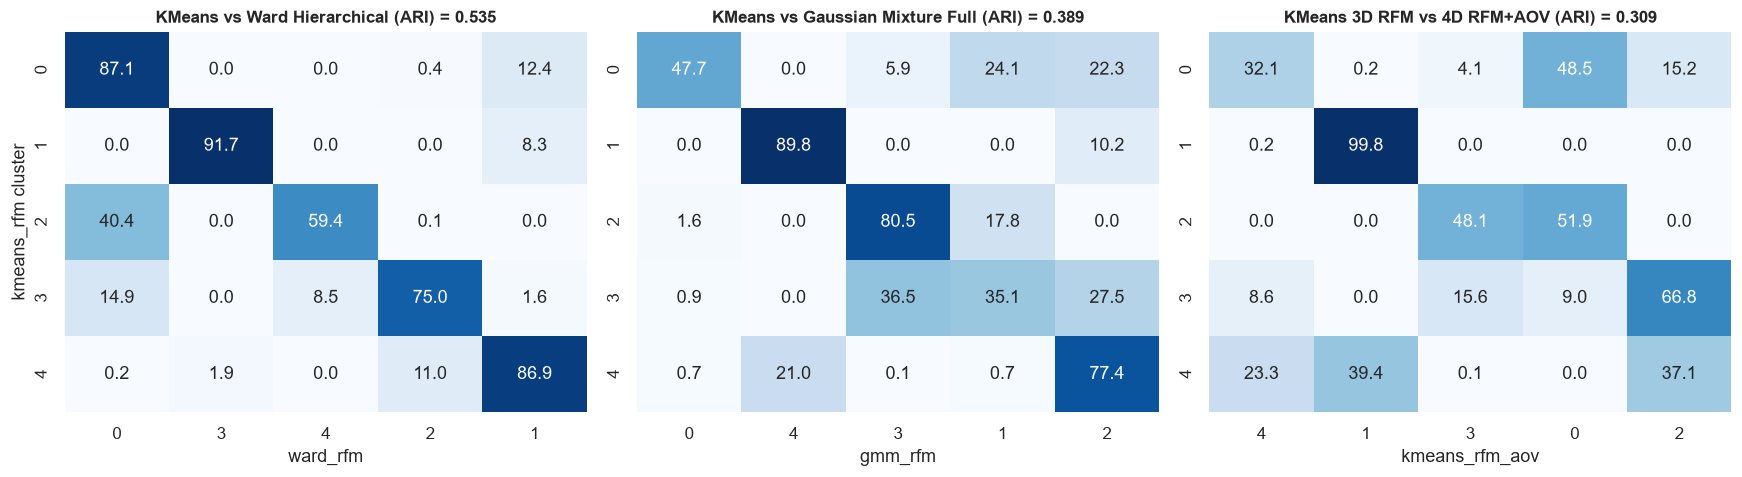


Assignments DataFrame shape: (5256, 4)

5 Sample Rows Comparing Assignments Across Methods (Random Seed = 42):


,recency_days,frequency,monetary,aov,kmeans_rfm,gmm_rfm,ward_rfm,kmeans_rfm_aov
Customer ID,,,,,,,,
16089,295.42,2,263.49,131.74,2,1,0,3
14384,409.59,1,58.50,58.50,2,3,4,3
16491,322.35,1,801.66,801.66,0,3,0,0
13016,32.38,1,425.25,425.25,3,3,2,2
13171,208.41,1,140.35,140.35,2,3,4,3


In [7]:
from src.segmentation import evaluate_robustness_checks

CHOSEN_K = 5
AOV_COLS = ["recency_days", "frequency", "monetary", "aov"]

# Fit final K=5 unified sklearn Pipeline on T_seg snapshot ONLY (pre-2011-09-10)
rfm_pipeline = build_rfm_pipeline(
    n_clusters=CHOSEN_K,
    feature_cols=RFM_COLUMNS,
    recency_transform="sqrt",
    n_init=20,
    random_state=RANDOM_STATE,
)
kmeans_labels_seg = rfm_pipeline.fit_predict(rfm_seg_df)

# Verify pipeline[:-1] transform parity with X_seg_scaled
X_pipe_scaled = rfm_pipeline[:-1].transform(rfm_seg_df)
np.testing.assert_allclose(X_pipe_scaled, X_seg_scaled, atol=1e-12)

# Build 4D sensitivity preprocessor (sqrt(R) + log1p(F, M, aov) + StandardScaler)
aov_preprocessor = build_rfm_preprocessor(feature_cols=AOV_COLS, recency_transform="sqrt")
X_aov_scaled = aov_preprocessor.fit_transform(rfm_seg_df)

robust_summary_df, robust_assign_df = evaluate_robustness_checks(
    X_rfm_scaled=X_pipe_scaled,
    X_aov_scaled=X_aov_scaled,
    kmeans_labels=kmeans_labels_seg,
    n_clusters=CHOSEN_K,
    n_init=20,
    random_state=RANDOM_STATE,
)
robust_assign_df.index = rfm_seg_df.index

print("=" * 72)
print(f"STEP 5 SUMMARY: ROBUSTNESS & AOV SENSITIVITY CHECK (K = {CHOSEN_K})")
print("=" * 72)
display(robust_summary_df.drop(columns=["cluster_sizes"]))

print("\nCluster Size Distributions Across Methods:")
for _, r in robust_summary_df.iterrows():
    print(f"  {r['method']:38s} | min={r['min_cluster_pct']:5.2f}% | {r['cluster_sizes']}")

# Cross-tabulate cluster overlap (row-normalized %) vs KMeans baseline
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
comp_specs = [
    ("ward_rfm", "KMeans vs Ward Hierarchical (ARI)"),
    ("gmm_rfm", "KMeans vs Gaussian Mixture Full (ARI)"),
    ("kmeans_rfm_aov", "KMeans 3D RFM vs 4D RFM+AOV (ARI)"),
]

for ax, (col_name, title) in zip(axes, comp_specs):
    ct = pd.crosstab(
        robust_assign_df["kmeans_rfm"],
        robust_assign_df[col_name],
        normalize="index",
    ) * 100.0
    # Reorder columns by peak alignment for crisp diagonal visualization
    col_order = ct.idxmax(axis=0).sort_values().index.tolist()
    ct = ct[col_order]
    sns.heatmap(ct, annot=True, fmt=".1f", cmap="Blues", cbar=False, ax=ax)
    ari_val = robust_summary_df.loc[
        robust_summary_df["method"].str.contains(
            "Ward" if "ward" in col_name else ("Gaussian" if "gmm" in col_name else "Sensitivity")
        ),
        "ari_vs_kmeans",
    ].iloc[0]
    ax.set_title(f"{title} = {ari_val:.3f}", fontweight="bold", fontsize=11)
    ax.set_xlabel(col_name)
    ax.set_ylabel("kmeans_rfm cluster" if ax is axes[0] else "")

plt.tight_layout()
plt.show()

print(f"\nAssignments DataFrame shape: {robust_assign_df.shape}")
print("\n5 Sample Rows Comparing Assignments Across Methods (Random Seed = 42):")
sample_rob = rfm_seg_df[["recency_days", "frequency", "monetary", "aov"]].join(robust_assign_df)
display(sample_rob.sample(5, random_state=RANDOM_STATE).round(2))

## Step 6: Cluster Profiling, Visual Fingerprints & Candidate Naming *(STOP Point)*

### Why Profile Both Means, Medians, Revenue Share & Relative Ratios?
K-Means fits centroids in standardized `sqrt(R) / log1p(F, M)` space, which hides the true business magnitudes in raw pounds and days:
- **Means vs. Medians**: Because `monetary` and `frequency` are right-skewed even within segments, showing **both** mean and median proves whether a cluster's value comes from typical members or a few whales inside it.
- **Relative Means Heatmap (`Cluster Mean / Global Mean`)**: Immediately reveals *why* K-Means separated each segment (`1.0x` = cohort average; `< 1.0x` on `recency_days` means fresher buyers).
- **Radar Chart**: Visualizes multi-dimensional behavioral signatures simultaneously so CRM teams can translate math clusters into intuitive business personas and targeted retention/growth campaigns.

Cluster labels remain numeric IDs (`0..4`) below until stakeholder approval of final business names.

STEP 6 SUMMARY: CLUSTER PROFILES AT T_seg (K = 5, N = 5,256)
Full Cluster Profile Table (Sorted Descending by Mean Monetary):


,customers,cust_share_pct,mean_R,median_R,mean_F,median_F,mean_M,median_M,total_revenue,rev_share_pct,mean_aov,median_aov,mean_return_rate,median_return_rate,uk_share_pct
cluster,,,,,,,,,,,,,,,
1,480,9.13,32.81,16.60,27.56,19.0,16277.16,7850.64,7813039.19,57.56,535.24,386.74,0.17,0.15,92.08
4,1217,23.15,68.38,54.44,7.36,7.0,2778.48,2251.63,3381405.92,24.91,422.92,320.96,0.15,0.14,89.65
0,1128,21.46,302.63,296.38,3.60,3.0,1326.43,985.77,1496211.04,11.02,464.80,306.85,0.14,0.00,90.87
3,1024,19.48,78.31,73.02,2.02,2.0,506.25,441.17,518401.48,3.82,280.64,228.19,0.08,0.00,90.14
2,1407,26.77,401.01,371.60,1.21,1.0,259.86,231.93,365628.47,2.69,229.18,188.46,0.07,0.00,93.67



Cluster Means Relative to Global Mean (1.00 = Cohort Average):


,recency_days,frequency,monetary,aov,return_rate
cluster,,,,,
1,0.159,4.827,6.302,1.476,1.441
4,0.331,1.288,1.076,1.166,1.320
0,1.466,0.630,0.514,1.282,1.186
3,0.379,0.353,0.196,0.774,0.722
2,1.943,0.212,0.101,0.632,0.626


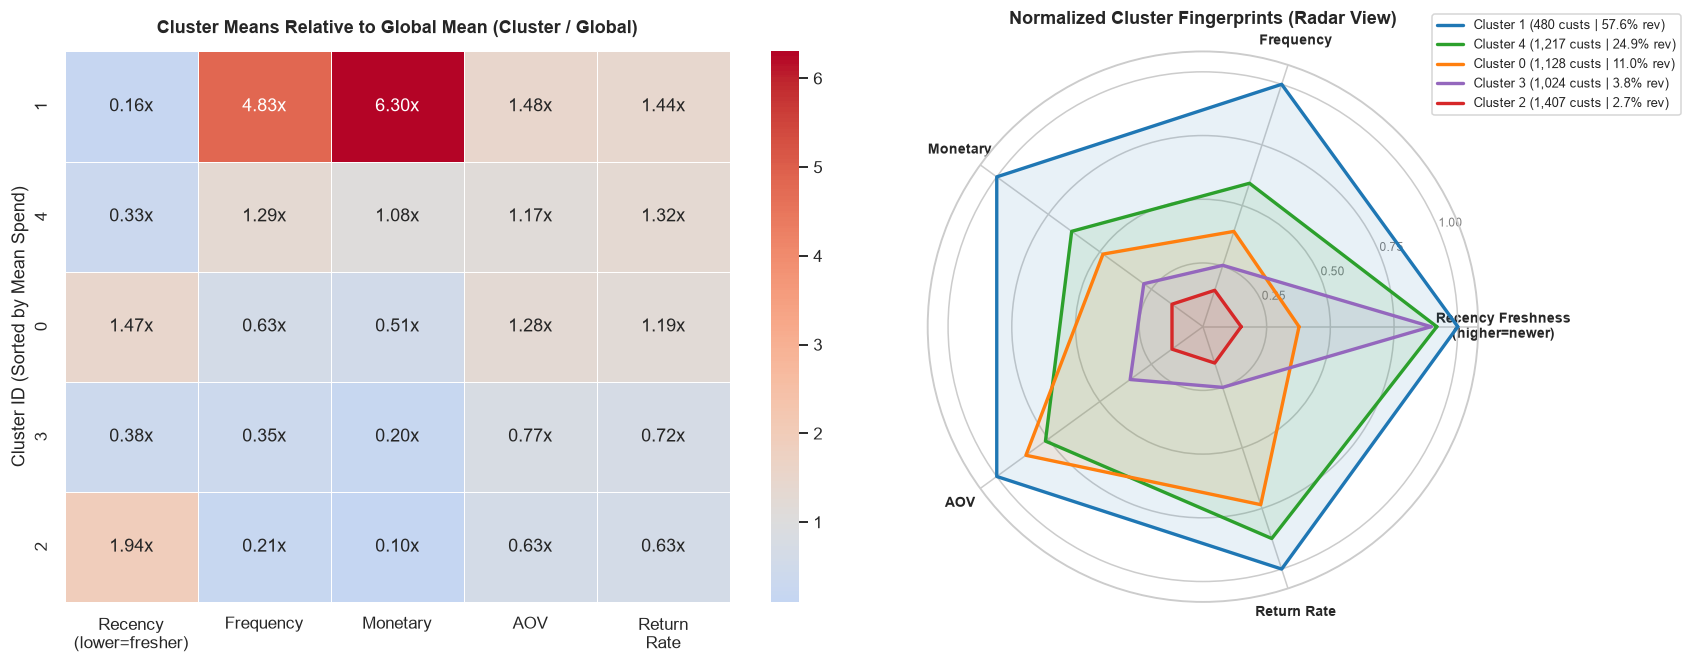


Cross-Tabulation: KMeans Clusters (rows) vs Rule-Based Segments (cols):


rule_segment,About to Sleep,At Risk (High Value),Champions,Hibernating / Lost,Loyal Customers,Need Attention,Potential Loyalists,Recent / New Customers
cluster,,,,,,,,
1,0,8,454,0,18,0,0,0
4,0,12,778,0,371,3,52,1
0,11,478,0,340,153,146,0,0
3,137,0,0,0,88,175,387,237
2,128,1,0,1263,1,14,0,0



5 Sample Rows with KMeans Numeric Cluster ID (Random Seed = 42):


,recency_days,frequency,monetary,aov,return_rate,cluster,RFM_code,rule_segment
Customer ID,,,,,,,,
16089,295.42,2,263.49,131.74,0.0,2,222,Hibernating / Lost
14384,409.59,1,58.50,58.50,0.0,2,111,Hibernating / Lost
16491,322.35,1,801.66,801.66,0.5,0,213,Hibernating / Lost
13016,32.38,1,425.25,425.25,0.0,3,512,Recent / New Customers
13171,208.41,1,140.35,140.35,0.0,2,311,About to Sleep


In [8]:
from src.segmentation import profile_clusters

rfm_seg_profiled_input = rfm_seg_df.copy()
rfm_seg_profiled_input["cluster"] = kmeans_labels_seg

profile_seg_df, rel_seg_df = profile_clusters(
    rfm_seg_profiled_input,
    labels=kmeans_labels_seg,
    extra_cols=("aov", "return_rate", "is_uk"),
)

print("=" * 72)
print(f"STEP 6 SUMMARY: CLUSTER PROFILES AT T_seg (K = {CHOSEN_K}, N = {len(rfm_seg_df):,})")
print("=" * 72)
print("Full Cluster Profile Table (Sorted Descending by Mean Monetary):")
display(profile_seg_df.round(2))

print("\nCluster Means Relative to Global Mean (1.00 = Cohort Average):")
display(rel_seg_df.round(3))

# Dual Visualization: Left = Relative Means Heatmap, Right = Polar Radar Chart
fig = plt.figure(figsize=(16, 6.2))
gs = fig.add_gridspec(1, 2, width_ratios=[1.15, 1.0])

ax_heat = fig.add_subplot(gs[0, 0])
annot_mat = rel_seg_df.map(lambda v: f"{v:.2f}x")
sns.heatmap(
    rel_seg_df,
    annot=annot_mat,
    fmt="",
    cmap="coolwarm",
    center=1.0,
    linewidths=0.6,
    ax=ax_heat,
)
# Swap palette intuition clearly via title (Green = low recency / Red-Orange = high spend relative ratio)
ax_heat.set_title("Cluster Means Relative to Global Mean (Cluster / Global)", fontweight="bold", pad=12)
ax_heat.set_ylabel("Cluster ID (Sorted by Mean Spend)")
ax_heat.set_xticklabels(
    ["Recency\n(lower=fresher)", "Frequency", "Monetary", "AOV", "Return\nRate"],
    rotation=0,
)

# Right: Polar Radar Chart using min-max normalized cluster profiles (with Freshness inverted)
radar_raw = profile_seg_df[["mean_R", "mean_F", "mean_M", "mean_aov", "mean_return_rate"]].copy()
radar_raw["freshness"] = radar_raw["mean_R"].max() + radar_raw["mean_R"].min() - radar_raw["mean_R"]
radar_cols = ["freshness", "mean_F", "mean_M", "mean_aov", "mean_return_rate"]
radar_labels = ["Recency Freshness\n(higher=newer)", "Frequency", "Monetary", "AOV", "Return Rate"]

radar_scaled = pd.DataFrame(index=radar_raw.index)
for col in radar_cols:
    vals = np.log1p(radar_raw[col]) if col in ("mean_F", "mean_M", "mean_aov") else radar_raw[col]
    vmin, vmax = float(vals.min()), float(vals.max())
    # Scale into [0.15, 1.0] so all spokes stay visible away from origin
    radar_scaled[col] = 0.15 + 0.85 * ((vals - vmin) / (vmax - vmin + 1e-12))

angles = np.linspace(0, 2 * np.pi, len(radar_cols), endpoint=False).tolist()
angles += angles[:1]

ax_rad = fig.add_subplot(gs[0, 1], polar=True)
palette = ["#1f77b4", "#2ca02c", "#ff7f0e", "#9467bd", "#d62728"]
for idx_pos, (cl_id, row_vals) in enumerate(radar_scaled.iterrows()):
    values = row_vals.tolist() + row_vals.tolist()[:1]
    cust_cnt = int(profile_seg_df.loc[cl_id, "customers"])
    rev_pct = float(profile_seg_df.loc[cl_id, "rev_share_pct"])
    lbl = f"Cluster {cl_id} ({cust_cnt:,} custs | {rev_pct:.1f}% rev)"
    ax_rad.plot(angles, values, linewidth=2.2, label=lbl, color=palette[idx_pos % len(palette)])
    ax_rad.fill(angles, values, alpha=0.10, color=palette[idx_pos % len(palette)])

ax_rad.set_xticks(angles[:-1])
ax_rad.set_xticklabels(radar_labels, fontsize=9, fontweight="bold")
ax_rad.set_ylim(0, 1.08)
ax_rad.set_yticks([0.25, 0.50, 0.75, 1.00])
ax_rad.set_yticklabels(["0.25", "0.50", "0.75", "1.00"], fontsize=8, color="gray")
ax_rad.set_title("Normalized Cluster Fingerprints (Radar View)", fontweight="bold", pad=18)
ax_rad.legend(loc="upper right", bbox_to_anchor=(1.38, 1.08), fontsize=8.5)

plt.tight_layout()
plt.show()

# Overlap check against Step 2 rule-based baseline
print("\nCross-Tabulation: KMeans Clusters (rows) vs Rule-Based Segments (cols):")
ct_rule = pd.crosstab(rfm_seg_profiled_input["cluster"], rfm_seg_with_rules["rule_segment"]).loc[profile_seg_df.index]
display(ct_rule)

print("\n5 Sample Rows with KMeans Numeric Cluster ID (Random Seed = 42):")
sample_prof = rfm_seg_profiled_input[["recency_days", "frequency", "monetary", "aov", "return_rate", "cluster"]].join(
    rfm_seg_with_rules[["RFM_code", "rule_segment"]]
)
display(sample_prof.sample(5, random_state=RANDOM_STATE).round(2))

### Locked Step 6 Decision: Approved Segment Names (`K = 5`)
- **`Cluster 1` -> `VIP Champions`** (`9.13%` customers / `57.56%` historical spend)
- **`Cluster 4` -> `Loyal Regulars`** (`23.15%` customers / `24.91%` historical spend)
- **`Cluster 0` -> `At-Risk Repeaters`** (`21.46%` customers / `11.02%` historical spend)
- **`Cluster 3` -> `Promising Recent Buyers`** (`19.48%` customers / `3.82%` historical spend)
- **`Cluster 2` -> `Hibernating / Lost`** (`26.77%` customers / `2.69%` historical spend)

---

## Step 7: External Validation Against Unseen Future Spend (`[2011-09-10, 2011-12-09)`)

### Strict Non-Leakage Statement
> **VALIDATION ONLY**: Every transformation (`StandardScaler`), centroid (`KMeans`), cluster count (`K = 5`), and business segment name was frozen strictly using transactions **before `2011-09-10 00:00:00`**. The real 90-day future target inside `[2011-09-10, 2011-12-09)` was **never** used to fit, tune, or name clusters—it serves purely as an out-of-time business ground truth test.

### Why Measure Reactivation, Kruskal-Wallis $\eta^2$ on `log1p(target)`, and Top-Segment Spend Share?
Internal geometric metrics (Silhouette, Inertia) only prove clusters look neat in transformed space. Business stakeholders care whether segments **predict real future commercial behavior**:
1. **Monotonic Reactivation & Future Spend Separation**: Do `VIP Champions` actually return and spend dramatically more in `[2011-09-10, 2011-12-09)` than `Loyal Regulars`, `Promising`, `At-Risk`, and `Hibernating / Lost`?
2. **Comparison Against Rule-Based RFM Baseline**: Using **Kruskal-Wallis H / p-value**, **effect size $\eta^2$ on `log1p(target)`** (variance of log future spend explained between segments), and **top-segment future spend share**, we test whether 3D K-Means outperforms the Step 2 rule-based baseline (`8` segments).

STEP 7 SUMMARY: EXTERNAL FUTURE VALIDATION [2011-09-10, 2011-12-09)
(POST-HOC VALIDATION ONLY — TARGET NEVER INFLUENCED FITTING OR TUNING)
Validated Cohort Size       : 5,256 pre-T_seg customers
Total Unseen 90d Spend      : £2,808,039.41 (overall reactivation: 43.51%)

K-Means (K = 5) External Validation by Business Segment:


,customers,cust_share_pct,active_customers,reactivation_rate_pct,mean_target,median_target,q90_target,total_future_spend,future_spend_share_pct
segment,,,,,,,,,
VIP Champions,480,9.13,433,90.21,3241.48,1324.21,5135.28,1555911.36,55.41
Loyal Regulars,1217,23.15,817,67.13,555.55,309.30,1335.09,676100.41,24.08
Promising Recent Buyers,1024,19.48,452,44.14,273.84,0.00,718.39,280416.08,9.99
At-Risk Repeaters,1128,21.46,365,32.36,192.66,0.00,603.73,217324.49,7.74
Hibernating / Lost,1407,26.77,220,15.64,55.64,0.00,193.39,78287.07,2.79



Rule-Based Baseline (8 Segments) External Validation:


,customers,cust_share_pct,active_customers,reactivation_rate_pct,mean_target,median_target,q90_target,total_future_spend,future_spend_share_pct
segment,,,,,,,,,
Champions,1232,23.44,986,80.03,1639.90,649.43,2773.44,2020352.81,71.95
Potential Loyalists,439,8.35,223,50.80,410.80,49.98,872.03,180341.46,6.42
Loyal Customers,631,12.01,346,54.83,356.84,111.83,996.45,225168.80,8.02
Recent / New Customers,238,4.53,110,46.22,267.44,0.00,888.39,63651.06,2.27
At Risk (High Value),499,9.49,148,29.66,237.82,0.00,793.92,118671.68,4.23
Need Attention,338,6.43,117,34.62,167.27,0.00,554.15,56535.79,2.01
About to Sleep,276,5.25,55,19.93,92.33,0.00,319.50,25483.89,0.91
Hibernating / Lost,1603,30.50,302,18.84,73.51,0.00,296.57,117833.92,4.20



Head-to-Head Future Spend Separation Comparison:


,approach,n_segments,kruskal_h,kruskal_pvalue,kruskal_eta2,anova_f_log1p,anova_eta2_log1p,top_segment_spend_share_pct,top_segment_mean_target,reactivation_spread_pp
0,"K-Means (K = 5, 3D RFM Pipeline)",5,1636.14,0.0,0.3108,534.56,0.2894,55.41,3241.48,74.57
1,Rule-Based RFM Baseline (8 Segments),8,1538.33,0.0,0.2918,287.16,0.2769,71.95,1639.90,61.19


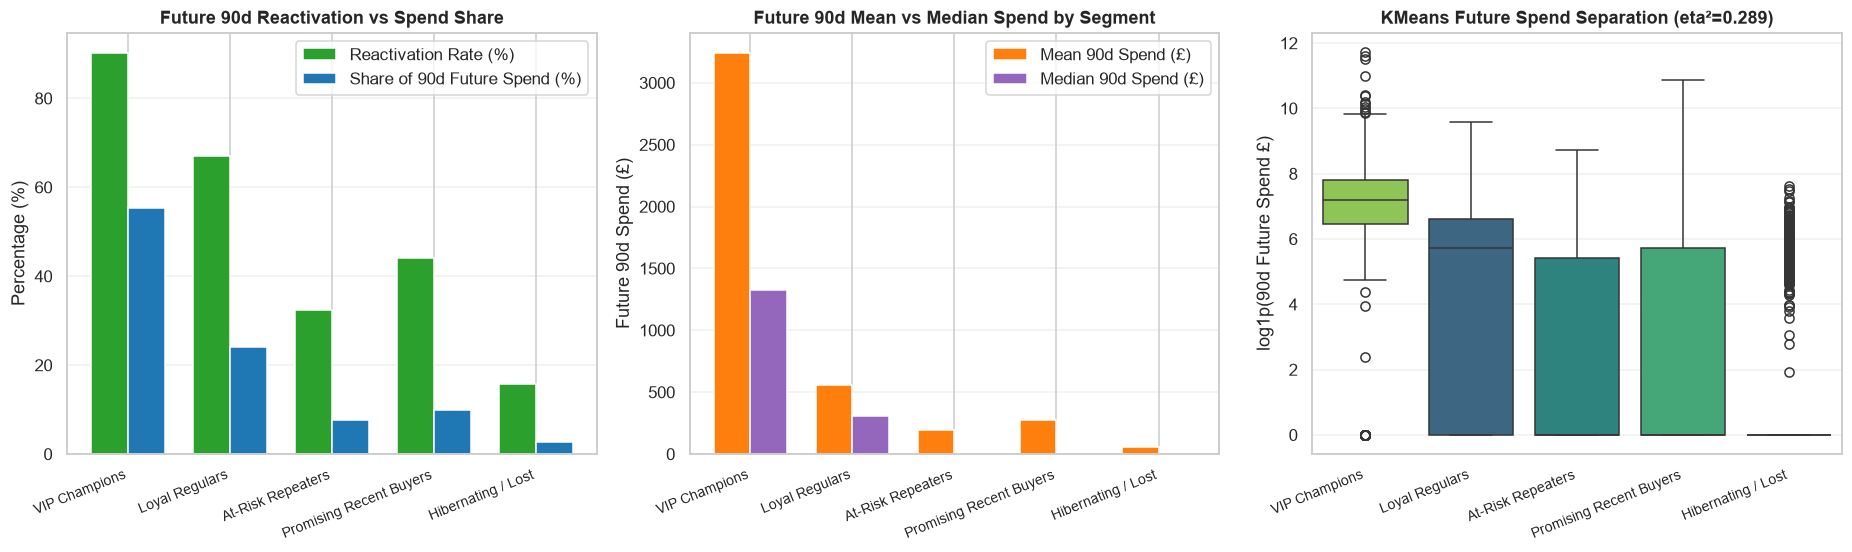


Validated DataFrame shape: (5256, 33)

5 Sample Customers with Future 90d Target Validation (Random Seed = 42):


,recency_days,frequency,monetary,segment,rule_segment,target,target_active
Customer ID,,,,,,,
16089,295.42,2,263.49,Hibernating / Lost,Hibernating / Lost,0.00,0
14384,409.59,1,58.50,Hibernating / Lost,Hibernating / Lost,0.00,0
16491,322.35,1,801.66,At-Risk Repeaters,Hibernating / Lost,731.50,1
13016,32.38,1,425.25,Promising Recent Buyers,Recent / New Customers,364.64,1
13171,208.41,1,140.35,Hibernating / Lost,About to Sleep,328.06,1


In [9]:
from src.features import build_target
from src.segmentation import evaluate_external_validation

SEGMENT_NAME_MAP = {
    1: "VIP Champions",
    4: "Loyal Regulars",
    0: "At-Risk Repeaters",
    3: "Promising Recent Buyers",
    2: "Hibernating / Lost",
}
ORDERED_SEGMENTS = [
    "VIP Champions",
    "Loyal Regulars",
    "At-Risk Repeaters",
    "Promising Recent Buyers",
    "Hibernating / Lost",
]

# Build unseen 90d future target strictly for all T_seg customers (5,256 rows)
seg_target_df = build_target(
    sales_clean,
    returns_clean,
    cutoff=T_SEG,
    horizon_days=90,
    eligible_ids=rfm_seg_df.index,
)
assert len(seg_target_df) == len(rfm_seg_df), "Target length mismatch!"
assert set(seg_target_df.index) == set(rfm_seg_df.index), "Index mismatch!"

rfm_seg_validated_df = rfm_seg_profiled_input.copy()
rfm_seg_validated_df["segment"] = rfm_seg_validated_df["cluster"].map(SEGMENT_NAME_MAP)
rfm_seg_validated_df["rule_segment"] = rfm_seg_with_rules["rule_segment"]
rfm_seg_validated_df = rfm_seg_validated_df.join(seg_target_df)

# Evaluate both K-Means (5 segments) and Rule-Based Baseline (8 segments)
kmeans_val_df, kmeans_val_stats = evaluate_external_validation(
    rfm_seg_validated_df["target"], rfm_seg_validated_df["segment"]
)
rule_val_df, rule_val_stats = evaluate_external_validation(
    rfm_seg_validated_df["target"], rfm_seg_validated_df["rule_segment"]
)

comparison_df = pd.DataFrame([
    {"approach": "K-Means (K = 5, 3D RFM Pipeline)", **kmeans_val_stats},
    {"approach": "Rule-Based RFM Baseline (8 Segments)", **rule_val_stats},
])

total_future_rev_all = float(rfm_seg_validated_df["target"].sum())
overall_reactivation = float((rfm_seg_validated_df["target"] > 0).mean() * 100.0)

print("=" * 72)
print("STEP 7 SUMMARY: EXTERNAL FUTURE VALIDATION [2011-09-10, 2011-12-09)")
print("(POST-HOC VALIDATION ONLY — TARGET NEVER INFLUENCED FITTING OR TUNING)")
print("=" * 72)
print(f"Validated Cohort Size       : {len(rfm_seg_validated_df):,} pre-T_seg customers")
print(f"Total Unseen 90d Spend      : £{total_future_rev_all:,.2f} (overall reactivation: {overall_reactivation:.2f}%)")

print("\nK-Means (K = 5) External Validation by Business Segment:")
display(kmeans_val_df.round(2))

print("\nRule-Based Baseline (8 Segments) External Validation:")
display(rule_val_df.round(2))

print("\nHead-to-Head Future Spend Separation Comparison:")
display(
    comparison_df.round({
        "kruskal_h": 2,
        "kruskal_eta2": 4,
        "anova_f_log1p": 2,
        "anova_eta2_log1p": 4,
        "top_segment_spend_share_pct": 2,
        "top_segment_mean_target": 2,
        "reactivation_spread_pp": 2,
    })
)

# 3-panel visualization comparing KMeans segments vs future spend & Rule baseline
fig, axes = plt.subplots(1, 3, figsize=(17, 5.2))

km_plot = kmeans_val_df.reindex(ORDERED_SEGMENTS)
x_pos = np.arange(len(km_plot))

# Panel 1: Reactivation rate & Future spend share
width = 0.36
axes[0].bar(x_pos - width / 2, km_plot["reactivation_rate_pct"], width, label="Reactivation Rate (%)", color="#2ca02c")
axes[0].bar(x_pos + width / 2, km_plot["future_spend_share_pct"], width, label="Share of 90d Future Spend (%)", color="#1f77b4")
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(km_plot.index, rotation=22, ha="right", fontsize=9)
axes[0].set_ylabel("Percentage (%)")
axes[0].set_title("Future 90d Reactivation vs Spend Share", fontweight="bold")
axes[0].legend()
axes[0].grid(axis="y", alpha=0.3)

# Panel 2: Mean vs Median unseen 90d spend
axes[1].bar(x_pos - width / 2, km_plot["mean_target"], width, label="Mean 90d Spend (£)", color="#ff7f0e")
axes[1].bar(x_pos + width / 2, km_plot["median_target"], width, label="Median 90d Spend (£)", color="#9467bd")
axes[1].set_xticks(x_pos)
axes[1].set_xticklabels(km_plot.index, rotation=22, ha="right", fontsize=9)
axes[1].set_ylabel("Future 90d Spend (£)")
axes[1].set_title("Future 90d Mean vs Median Spend by Segment", fontweight="bold")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

# Panel 3: Boxplot of log1p(target) by ordered KMeans segment
rfm_seg_validated_df["log1p_target"] = np.log1p(rfm_seg_validated_df["target"])
sns.boxplot(
    data=rfm_seg_validated_df,
    x="segment",
    y="log1p_target",
    order=ORDERED_SEGMENTS,
    hue="segment",
    legend=False,
    palette="viridis",
    ax=axes[2],
)
axes[2].set_xticks(range(len(ORDERED_SEGMENTS)))
axes[2].set_xticklabels(ORDERED_SEGMENTS, rotation=22, ha="right", fontsize=9)
axes[2].set_xlabel("")
axes[2].set_ylabel("log1p(90d Future Spend £)")
axes[2].set_title(
    f"KMeans Future Spend Separation (eta²={kmeans_val_stats['anova_eta2_log1p']:.3f})",
    fontweight="bold",
)
axes[2].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print(f"\nValidated DataFrame shape: {rfm_seg_validated_df.shape}")
print("\n5 Sample Customers with Future 90d Target Validation (Random Seed = 42):")
sample_val_cols = ["recency_days", "frequency", "monetary", "segment", "rule_segment", "target", "target_active"]
display(rfm_seg_validated_df[sample_val_cols].sample(5, random_state=RANDOM_STATE).round(2))

## Step 8: Deployment Simulation (`2011-12-10` Live View & Segment Migration Matrix)

### Why Score `2011-12-10` Without Refitting the Pipeline?
In production batch scoring, the segmentation model frozen at `T_seg` (`2011-09-10`) defines stable business thresholds (`StandardScaler` mean/scale and K-Means centroids). If you refitted on `2011-12-10`, segment definitions themselves would shift simultaneously with customer behavior—making quarter-over-quarter CRM tracking impossible.

Calling **`rfm_pipeline.predict(rfm_deploy_df)`** (transform + predict **only, zero refit**):
1. Classifies all **`5,852`** active registered accounts at `2011-12-10` (including the **`596` new Q4 buyers**) in the exact same coordinate frame.
2. Lets us audit a **5x5 Segment Migration Matrix** across the **`5,256` shared customers**, revealing real upgrades (Q4 repeaters graduating to `Loyal Regulars` / `VIP Champions`) and churn decay (inactive buyers slipping into `At-Risk Repeaters` or `Hibernating / Lost`).

STEP 8 SUMMARY: DEPLOYMENT SCORING (2011-12-10) & MIGRATION MATRIX
(FROZEN PIPELINE VERIFIED — ZERO SCALER/CENTROID REFIT)
Deployment Cohort Shape    : (5852, 29) (total spend: £16,783,959.54)
Newly Acquired Q4 Buyers   : 596 accounts
Shared Longitudinal Cohort : 5,256 accounts | Stayed in same segment: 3,751 (71.37%)

Current-State Deployment Segment Profiles (2011-12-10, N = 5,852):


,customers,cust_share_pct,mean_R,median_R,mean_F,median_F,mean_M,median_M,total_revenue,rev_share_pct,mean_aov,median_aov,mean_return_rate,median_return_rate,uk_share_pct
segment,,,,,,,,,,,,,,,
VIP Champions,636,10.87,29.43,11.57,27.68,20.0,16448.21,8206.96,10461060.61,62.33,548.48,392.43,0.17,0.15,91.19
Loyal Regulars,1495,25.55,50.89,35.36,7.17,7.0,2563.90,2137.30,3833033.50,22.84,399.97,316.87,0.13,0.11,90.10
At-Risk Repeaters,1007,17.21,341.28,358.20,3.80,3.0,1397.42,1026.18,1407199.21,8.38,462.02,307.74,0.14,0.00,90.67
Promising Recent Buyers,1297,22.16,56.79,45.45,2.06,2.0,540.83,462.66,701457.47,4.18,297.77,232.60,0.08,0.00,90.36
Hibernating / Lost,1417,24.21,465.62,442.55,1.24,1.0,269.03,235.87,381208.74,2.27,231.84,188.40,0.07,0.00,93.30



Landing Distribution of 596 Newly Acquired Q4 Buyers (Post-2011-09-10):


,new_customers,share_pct
segment,,
VIP Champions,0,0.00
Loyal Regulars,61,10.23
At-Risk Repeaters,0,0.00
Promising Recent Buyers,535,89.77
Hibernating / Lost,0,0.00



Segment Migration Matrix — Customer Counts (Rows = 2011-09-10 -> Cols = 2011-12-10):


seg_2011_12_10,VIP Champions,Loyal Regulars,At-Risk Repeaters,Promising Recent Buyers,Hibernating / Lost
seg_2011_09_10,,,,,
VIP Champions,469,11,0,0,0
Loyal Regulars,164,900,151,2,0
At-Risk Repeaters,2,300,704,63,59
Promising Recent Buyers,1,209,152,491,171
Hibernating / Lost,0,14,0,206,1187



Segment Migration Matrix — Row-Normalized %:


seg_2011_12_10,VIP Champions,Loyal Regulars,At-Risk Repeaters,Promising Recent Buyers,Hibernating / Lost
seg_2011_09_10,,,,,
VIP Champions,97.7,2.3,0.0,0.0,0.0
Loyal Regulars,13.5,74.0,12.4,0.2,0.0
At-Risk Repeaters,0.2,26.6,62.4,5.6,5.2
Promising Recent Buyers,0.1,20.4,14.8,47.9,16.7
Hibernating / Lost,0.0,1.0,0.0,14.6,84.4


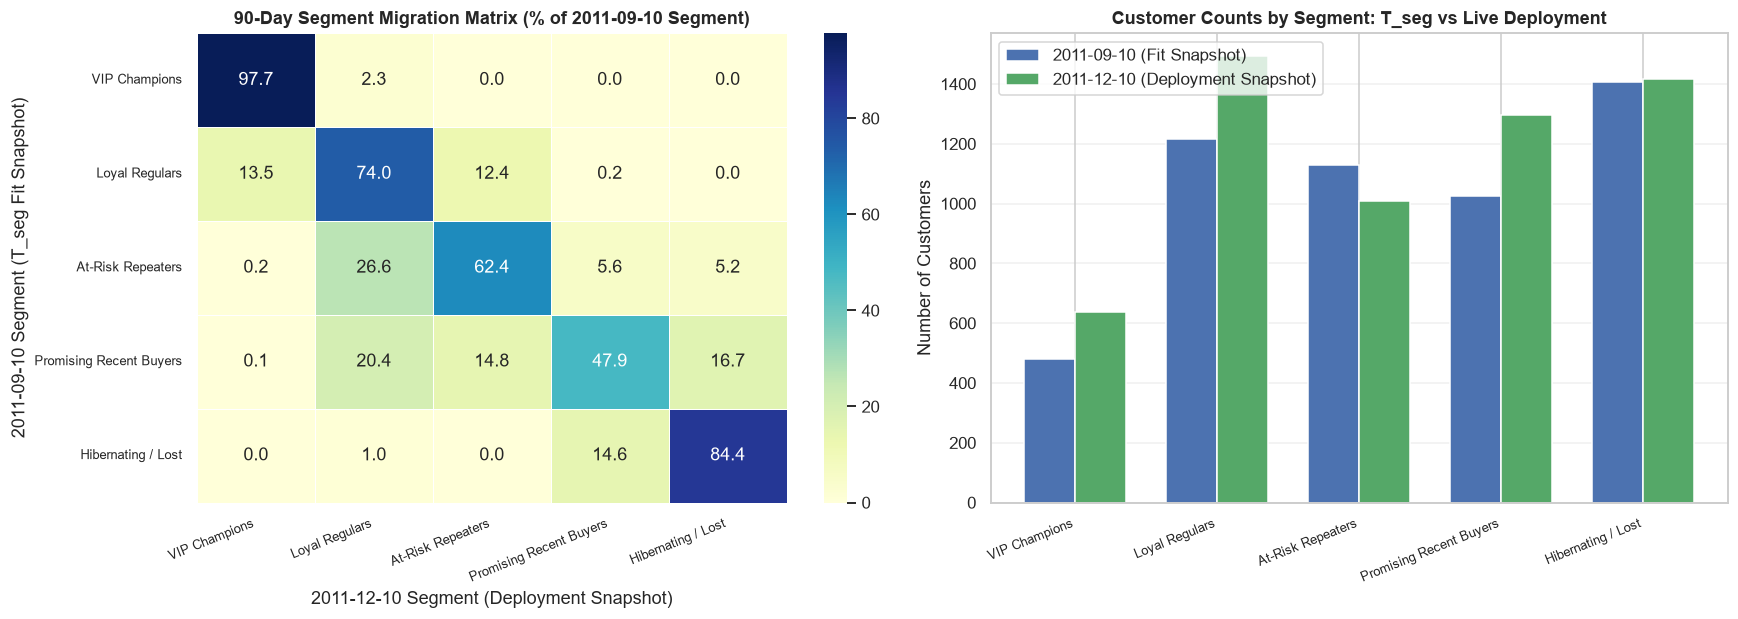


5 Sample Shared Customers Tracking T_seg -> 2011-12-10 Migration (Random Seed = 42):


,seg_2011_09_10,seg_2011_12_10,R_sep,R_dec,M_sep,M_dec
Customer ID,,,,,,
16089,Hibernating / Lost,Hibernating / Lost,295.42,386.42,263.49,263.49
14384,Hibernating / Lost,Hibernating / Lost,409.59,500.59,58.50,58.50
16491,At-Risk Repeaters,Promising Recent Buyers,322.35,46.57,801.66,1533.16
13016,Promising Recent Buyers,Promising Recent Buyers,32.38,73.41,425.25,789.89
13171,Hibernating / Lost,Promising Recent Buyers,208.41,21.56,140.35,468.41


In [10]:
# Record pre-predict frozen scaler & centroid parameters to assert ZERO refitting
scaler_mean_before = rfm_pipeline.named_steps["scaler"].mean_.copy()
scaler_scale_before = rfm_pipeline.named_steps["scaler"].scale_.copy()
centroids_before = rfm_pipeline.named_steps["kmeans"].cluster_centers_.copy()

# Predict on 2011-12-10 snapshot WITHOUT refitting
deploy_cluster_ids = rfm_pipeline.predict(rfm_deploy_df)

np.testing.assert_array_equal(rfm_pipeline.named_steps["scaler"].mean_, scaler_mean_before)
np.testing.assert_array_equal(rfm_pipeline.named_steps["scaler"].scale_, scaler_scale_before)
np.testing.assert_array_equal(rfm_pipeline.named_steps["kmeans"].cluster_centers_, centroids_before)

rfm_deploy_scored_df = rfm_deploy_df.copy()
rfm_deploy_scored_df["cluster"] = deploy_cluster_ids
rfm_deploy_scored_df["segment"] = rfm_deploy_scored_df["cluster"].map(SEGMENT_NAME_MAP)
rfm_deploy_scored_df["is_new_q4_buyer"] = ~rfm_deploy_scored_df.index.isin(rfm_seg_df.index)

# 1. Current-state deployment segment profile (2011-12-10, 5,852 buyers)
deploy_prof_raw, _ = profile_clusters(
    rfm_deploy_scored_df,
    labels=deploy_cluster_ids,
    extra_cols=("aov", "return_rate", "is_uk"),
)
deploy_prof_df = deploy_prof_raw.copy()
deploy_prof_df.insert(0, "segment", [SEGMENT_NAME_MAP[i] for i in deploy_prof_df.index])
deploy_prof_df = deploy_prof_df.set_index("segment").reindex(ORDERED_SEGMENTS)

# 2. New Q4 buyers breakdown (596 newly acquired customers)
new_q4_df = rfm_deploy_scored_df[rfm_deploy_scored_df["is_new_q4_buyer"]]
new_q4_dist = pd.DataFrame({
    "new_customers": new_q4_df["segment"].value_counts(),
    "share_pct": (new_q4_df["segment"].value_counts(normalize=True) * 100.0).round(2),
}).reindex(ORDERED_SEGMENTS).fillna(0.0)
new_q4_dist["new_customers"] = new_q4_dist["new_customers"].astype(int)

# 3. Migration Matrix across 5,256 customers present in BOTH T_seg and 2011-12-10
migration_df = pd.DataFrame(
    {
        "seg_2011_09_10": rfm_seg_validated_df["segment"],
        "seg_2011_12_10": rfm_deploy_scored_df.loc[rfm_seg_validated_df.index, "segment"],
        "R_sep": rfm_seg_validated_df["recency_days"],
        "R_dec": rfm_deploy_scored_df.loc[rfm_seg_validated_df.index, "recency_days"],
        "M_sep": rfm_seg_validated_df["monetary"],
        "M_dec": rfm_deploy_scored_df.loc[rfm_seg_validated_df.index, "monetary"],
    },
    index=rfm_seg_validated_df.index,
)
assert len(migration_df) == len(rfm_seg_df)

mig_counts = pd.crosstab(
    migration_df["seg_2011_09_10"],
    migration_df["seg_2011_12_10"],
).reindex(index=ORDERED_SEGMENTS, columns=ORDERED_SEGMENTS, fill_value=0)

mig_pct = pd.crosstab(
    migration_df["seg_2011_09_10"],
    migration_df["seg_2011_12_10"],
    normalize="index",
).reindex(index=ORDERED_SEGMENTS, columns=ORDERED_SEGMENTS, fill_value=0.0) * 100.0

same_seg_count = int(np.trace(mig_counts.to_numpy()))
same_seg_pct = same_seg_count / len(migration_df) * 100.0

print("=" * 72)
print("STEP 8 SUMMARY: DEPLOYMENT SCORING (2011-12-10) & MIGRATION MATRIX")
print("(FROZEN PIPELINE VERIFIED — ZERO SCALER/CENTROID REFIT)")
print("=" * 72)
print(f"Deployment Cohort Shape    : {rfm_deploy_scored_df.shape} (total spend: £{rfm_deploy_scored_df['monetary'].sum():,.2f})")
print(f"Newly Acquired Q4 Buyers   : {len(new_q4_df):,} accounts")
print(f"Shared Longitudinal Cohort : {len(migration_df):,} accounts | Stayed in same segment: {same_seg_count:,} ({same_seg_pct:.2f}%)")

print("\nCurrent-State Deployment Segment Profiles (2011-12-10, N = 5,852):")
display(deploy_prof_df.round(2))

print("\nLanding Distribution of 596 Newly Acquired Q4 Buyers (Post-2011-09-10):")
display(new_q4_dist)

print("\nSegment Migration Matrix — Customer Counts (Rows = 2011-09-10 -> Cols = 2011-12-10):")
display(mig_counts)

print("\nSegment Migration Matrix — Row-Normalized %:")
display(mig_pct.round(1))

# Side-by-side visuals: Migration Heatmap (%) & Longitudinal Size Shift
fig, axes = plt.subplots(1, 2, figsize=(16, 5.8))

sns.heatmap(
    mig_pct,
    annot=True,
    fmt=".1f",
    cmap="YlGnBu",
    linewidths=0.6,
    ax=axes[0],
)
axes[0].set_title("90-Day Segment Migration Matrix (% of 2011-09-10 Segment)", fontweight="bold")
axes[0].set_xlabel("2011-12-10 Segment (Deployment Snapshot)")
axes[0].set_ylabel("2011-09-10 Segment (T_seg Fit Snapshot)")
axes[0].set_xticklabels(ORDERED_SEGMENTS, rotation=22, ha="right", fontsize=8.5)
axes[0].set_yticklabels(ORDERED_SEGMENTS, rotation=0, fontsize=8.5)

comp_counts = pd.DataFrame({
    "2011-09-10 (n=5,256)": rfm_seg_validated_df["segment"].value_counts(),
    "2011-12-10 (n=5,852)": rfm_deploy_scored_df["segment"].value_counts(),
}).reindex(ORDERED_SEGMENTS)

x = np.arange(len(ORDERED_SEGMENTS))
w = 0.36
axes[1].bar(x - w / 2, comp_counts["2011-09-10 (n=5,256)"], w, label="2011-09-10 (Fit Snapshot)", color="#4c72b0")
axes[1].bar(x + w / 2, comp_counts["2011-12-10 (n=5,852)"], w, label="2011-12-10 (Deployment Snapshot)", color="#55a868")
axes[1].set_xticks(x)
axes[1].set_xticklabels(ORDERED_SEGMENTS, rotation=22, ha="right", fontsize=8.5)
axes[1].set_ylabel("Number of Customers")
axes[1].set_title("Customer Counts by Segment: T_seg vs Live Deployment", fontweight="bold")
axes[1].legend()
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\n5 Sample Shared Customers Tracking T_seg -> 2011-12-10 Migration (Random Seed = 42):")
display(migration_df.sample(5, random_state=RANDOM_STATE).round(2))

## Step 9: Executive Visualization (PCA 2D Projection, Segment Sizes & Revenue Asymmetry)

### Important Methodological Note on PCA
> **PCA IS FOR 2D DISPLAY ONLY**: Clustering (`KMeans`, $K=5$) was fit strictly in the original **3D standardized RFM space** (`[sqrt(recency_days), log1p(frequency), log1p(monetary)]`), preserving `100%` of variance across all three business dimensions. Here, we apply `PCA(n_components=2)` solely to project customer points and frozen K-Means centroids onto a readable 2D screen.

Below we present a 3-panel executive summary of the live `2011-12-10` deployment snapshot (`5,852` customers):
1. **PCA 2D Scatter + Projected Centroids (`★`)** colored by business segment.
2. **Segment Size Distribution** (customer headcount and share).
3. **Revenue Share vs. Customer Share** illustrating Pareto value concentration.

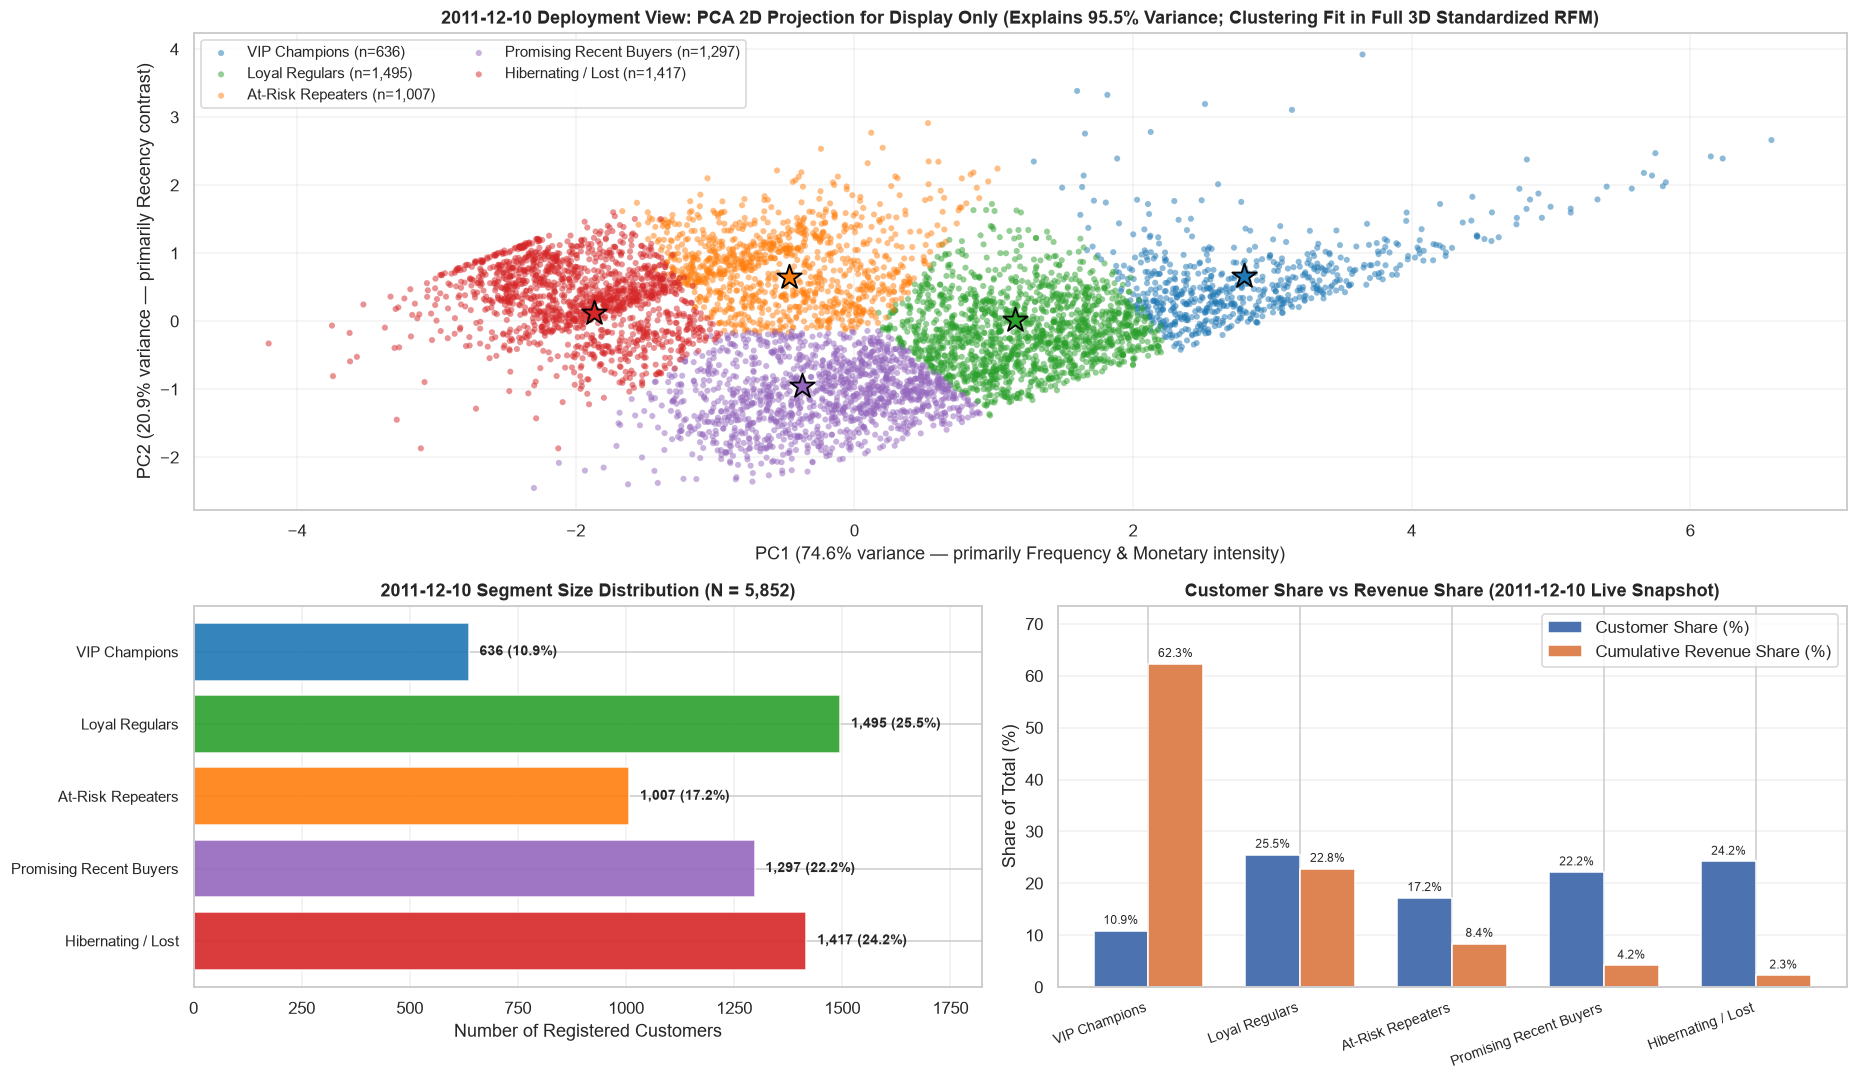

STEP 9 SUMMARY: PCA DISPLAY PROJECTION & EXECUTIVE CHARTS
PCA projection shape      : (5852, 5)
PC1 variance explained    : 74.62%
PC2 variance explained    : 20.93%
Total 2D variance shown   : 95.55% (clustering ran in 100% 3D RFM space)

Segment Share Summary (2011-12-10):


,customers,cust_share_pct,total_revenue,rev_share_pct
segment,,,,
VIP Champions,636,10.87,10461060.61,62.33
Loyal Regulars,1495,25.55,3833033.50,22.84
At-Risk Repeaters,1007,17.21,1407199.21,8.38
Promising Recent Buyers,1297,22.16,701457.47,4.18
Hibernating / Lost,1417,24.21,381208.74,2.27



5 Sample Rows with PCA 2D Display Coordinates (Random Seed = 42):


,segment,cluster,monetary,PC1,PC2
Customer ID,,,,,
15684,Hibernating / Lost,2,173.95,-1.807,0.803
15271,VIP Champions,1,4528.54,2.723,0.213
15394,VIP Champions,1,5286.80,2.207,-0.053
12369,At-Risk Repeaters,0,1511.15,-0.645,1.122
13443,At-Risk Repeaters,0,1269.37,-0.372,1.443


In [11]:
from sklearn.decomposition import PCA

# Compute 2D PCA display coordinates on standardized 2011-12-10 RFM features
X_deploy_scaled = rfm_pipeline[:-1].transform(rfm_deploy_df)
pca_display = PCA(n_components=2, random_state=RANDOM_STATE)
coords_2d = pca_display.fit_transform(X_deploy_scaled)
centroids_2d = pca_display.transform(rfm_pipeline.named_steps["kmeans"].cluster_centers_)
exp_var = pca_display.explained_variance_ratio_ * 100.0

pca_view_df = pd.DataFrame(
    {
        "segment": rfm_deploy_scored_df["segment"],
        "cluster": rfm_deploy_scored_df["cluster"],
        "monetary": rfm_deploy_scored_df["monetary"],
        "PC1": coords_2d[:, 0],
        "PC2": coords_2d[:, 1],
    },
    index=rfm_deploy_scored_df.index,
)

# Consistent color mapping aligned to ORDERED_SEGMENTS
seg_colors = {
    "VIP Champions": "#1f77b4",
    "Loyal Regulars": "#2ca02c",
    "At-Risk Repeaters": "#ff7f0e",
    "Promising Recent Buyers": "#9467bd",
    "Hibernating / Lost": "#d62728",
}

fig = plt.figure(figsize=(17, 10))
gs = fig.add_gridspec(2, 2, height_ratios=[1.25, 1.0])

# Top full-width Panel: PCA 2D Scatter
ax_pca = fig.add_subplot(gs[0, :])
for seg_name in ORDERED_SEGMENTS:
    sub = pca_view_df[pca_view_df["segment"] == seg_name]
    ax_pca.scatter(
        sub["PC1"],
        sub["PC2"],
        s=16,
        alpha=0.50,
        color=seg_colors[seg_name],
        label=f"{seg_name} (n={len(sub):,})",
        edgecolors="none",
    )

# Overlay projected KMeans centroids
for cl_id, seg_name in SEGMENT_NAME_MAP.items():
    cx, cy = centroids_2d[cl_id]
    ax_pca.scatter(
        cx,
        cy,
        marker="*",
        s=280,
        color=seg_colors[seg_name],
        edgecolors="black",
        linewidths=1.2,
        zorder=5,
    )

ax_pca.set_title(
    f"2011-12-10 Deployment View: PCA 2D Projection for Display Only (Explains {exp_var.sum():.1f}% Variance; Clustering Fit in Full 3D Standardized RFM)",
    fontweight="bold",
    fontsize=12,
)
ax_pca.set_xlabel(f"PC1 ({exp_var[0]:.1f}% variance — primarily Frequency & Monetary intensity)")
ax_pca.set_ylabel(f"PC2 ({exp_var[1]:.1f}% variance — primarily Recency contrast)")
ax_pca.legend(loc="upper left", frameon=True, ncol=2, fontsize=9.5)
ax_pca.grid(True, alpha=0.25)

# Bottom Left: Segment Size Horizontal Bars
ax_size = fig.add_subplot(gs[1, 0])
rev_order = ORDERED_SEGMENTS[::-1]
counts_ord = deploy_prof_df.loc[rev_order, "customers"]
pcts_ord = deploy_prof_df.loc[rev_order, "cust_share_pct"]
y_idx = np.arange(len(rev_order))
bars = ax_size.barh(
    y_idx,
    counts_ord,
    color=[seg_colors[s] for s in rev_order],
    alpha=0.90,
)
ax_size.set_yticks(y_idx)
ax_size.set_yticklabels(rev_order, fontsize=9.5)
ax_size.set_xlabel("Number of Registered Customers")
ax_size.set_title("2011-12-10 Segment Size Distribution (N = 5,852)", fontweight="bold")
ax_size.set_xlim(0, counts_ord.max() * 1.22)
for bar, cnt, pct in zip(bars, counts_ord, pcts_ord):
    ax_size.text(
        bar.get_width() + 25,
        bar.get_y() + bar.get_height() / 2,
        f"{int(cnt):,} ({pct:.1f}%)",
        va="center",
        fontsize=9,
        fontweight="bold",
    )
ax_size.grid(axis="x", alpha=0.3)

# Bottom Right: Revenue Share vs Customer Share
ax_rev = fig.add_subplot(gs[1, 1])
x_pos = np.arange(len(ORDERED_SEGMENTS))
w = 0.36
cust_sh = deploy_prof_df.loc[ORDERED_SEGMENTS, "cust_share_pct"]
rev_sh = deploy_prof_df.loc[ORDERED_SEGMENTS, "rev_share_pct"]

b1 = ax_rev.bar(x_pos - w / 2, cust_sh, w, label="Customer Share (%)", color="#4c72b0")
b2 = ax_rev.bar(x_pos + w / 2, rev_sh, w, label="Cumulative Revenue Share (%)", color="#dd8452")
ax_rev.set_xticks(x_pos)
ax_rev.set_xticklabels(ORDERED_SEGMENTS, rotation=20, ha="right", fontsize=9)
ax_rev.set_ylabel("Share of Total (%)")
ax_rev.set_ylim(0, max(rev_sh.max(), cust_sh.max()) * 1.18)
ax_rev.set_title("Customer Share vs Revenue Share (2011-12-10 Live Snapshot)", fontweight="bold")
for bar in list(b1) + list(b2):
    val = bar.get_height()
    ax_rev.text(
        bar.get_x() + bar.get_width() / 2,
        val + 0.8,
        f"{val:.1f}%",
        ha="center",
        va="bottom",
        fontsize=8,
    )
ax_rev.legend()
ax_rev.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("=" * 72)
print("STEP 9 SUMMARY: PCA DISPLAY PROJECTION & EXECUTIVE CHARTS")
print("=" * 72)
print(f"PCA projection shape      : {pca_view_df.shape}")
print(f"PC1 variance explained    : {exp_var[0]:.2f}%")
print(f"PC2 variance explained    : {exp_var[1]:.2f}%")
print(f"Total 2D variance shown   : {exp_var.sum():.2f}% (clustering ran in 100% 3D RFM space)")
print("\nSegment Share Summary (2011-12-10):")
display(deploy_prof_df[["customers", "cust_share_pct", "total_revenue", "rev_share_pct"]].round(2))

print("\n5 Sample Rows with PCA 2D Display Coordinates (Random Seed = 42):")
display(pca_view_df.sample(5, random_state=RANDOM_STATE).round(3))

## Step 10: Export Fitted Pipeline, Segment Assignments, Profiles & Parity Verification

### Why Save Both `joblib` Pipeline and Parquet/CSV Outputs?
1. **`models/rfm_kmeans_k5_pipeline.joblib`**: Persists the **single unified `sklearn` `Pipeline`** (`transform` $\rightarrow$ `scaler` $\rightarrow$ `kmeans`) using top-level module functions in `src/segmentation.py`, so downstream dashboards or batch jobs can reload and call `.predict(new_customers_df)` with zero training-serving skew.
2. **`data/processed/segmentation/*.parquet`**: Preserves exact dtypes, `Customer ID` index, cluster IDs, approved business segment labels, and validation outcomes for `T_seg` (`2011-09-10`, `5,256` buyers) and live deployment (`2011-12-10`, `5,852` buyers).
3. **`segment_profiles.parquet` & `segment_profiles.csv`**: Dual-format summary table pairing exact metrics with CRM action playbooks (Parquet for code, CSV for non-technical stakeholders / Excel).

In [12]:
import joblib

MODELS_DIR = PROJECT_ROOT / "models"
SEG_OUT_DIR = DATA_PROCESSED / "segmentation"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
SEG_OUT_DIR.mkdir(parents=True, exist_ok=True)

# 1. Save frozen unified sklearn Pipeline & verify round-trip predict parity
pipeline_path = MODELS_DIR / "rfm_kmeans_k5_pipeline.joblib"
joblib.dump(rfm_pipeline, pipeline_path)

reloaded_pipeline = joblib.load(pipeline_path)
reloaded_pred = reloaded_pipeline.predict(rfm_deploy_df)
np.testing.assert_array_equal(reloaded_pred, deploy_cluster_ids)

# 2. Export segment assignments for both T_seg (5,256) and Deployment (5,852) snapshots
t_seg_export_cols = [
    "recency_days", "frequency", "monetary", "aov", "return_rate",
    "is_single_invoice", "is_uk", "country",
    "cluster", "segment", "rule_segment",
    "target", "target_net", "target_active",
]
t_seg_assign_out = rfm_seg_validated_df[t_seg_export_cols].copy()
t_seg_assign_path = SEG_OUT_DIR / "segments_t_seg_2011-09-10.parquet"
t_seg_assign_out.to_parquet(t_seg_assign_path, index=True)

deploy_export_df = rfm_deploy_scored_df[[
    "recency_days", "frequency", "monetary", "aov", "return_rate",
    "is_single_invoice", "is_uk", "country",
    "cluster", "segment", "is_new_q4_buyer",
]].join(pca_view_df[["PC1", "PC2"]])
deploy_assign_path = SEG_OUT_DIR / "segments_deploy_2011-12-10.parquet"
deploy_export_df.to_parquet(deploy_assign_path, index=True)

# 3. Combine Deployment (2011-12-10) + Future Validation (T_seg -> 90d) + CRM Playbook
CRM_ACTIONS = {
    "VIP Champions": "Dedicated B2B account rep, priority inventory allocation, early Q4 catalog access, volume rebates, proactive return concierge.",
    "Loyal Regulars": "Cross-sell SKU breadth bundles, loyalty free-shipping thresholds to graduate top buyers to VIP, churn alert if recency > 90d.",
    "At-Risk Repeaters": "#1 win-back priority: personalized restock outreach, Q4 reactivation incentive, account check-in for supplier switch or return friction.",
    "Promising Recent Buyers": "Day-60 onboarding nurture cadence targeting 2nd/3rd repeat order via starter bundles and seasonal lookbooks.",
    "Hibernating / Lost": "Zero paid media spend; low-cost automated Q4 clearance blast only and suppress chronic non-openers.",
}
INV_SEG_MAP = {v: k for k, v in SEGMENT_NAME_MAP.items()}

segment_profiles_out = pd.DataFrame({
    "cluster_id": [INV_SEG_MAP[s] for s in ORDERED_SEGMENTS],
    "deploy_customers": deploy_prof_df["customers"].astype(int),
    "deploy_cust_share_pct": deploy_prof_df["cust_share_pct"].round(2),
    "deploy_mean_R_days": deploy_prof_df["mean_R"].round(2),
    "deploy_median_R_days": deploy_prof_df["median_R"].round(2),
    "deploy_mean_F": deploy_prof_df["mean_F"].round(2),
    "deploy_median_F": deploy_prof_df["median_F"].round(1),
    "deploy_mean_M_gbp": deploy_prof_df["mean_M"].round(2),
    "deploy_median_M_gbp": deploy_prof_df["median_M"].round(2),
    "deploy_total_rev_gbp": deploy_prof_df["total_revenue"].round(2),
    "deploy_rev_share_pct": deploy_prof_df["rev_share_pct"].round(2),
    "deploy_mean_return_rate": deploy_prof_df["mean_return_rate"].round(3),
    "t_seg_customers": kmeans_val_df.loc[ORDERED_SEGMENTS, "customers"].astype(int),
    "t_seg_90d_reactivation_pct": kmeans_val_df.loc[ORDERED_SEGMENTS, "reactivation_rate_pct"].round(2),
    "t_seg_90d_mean_target_gbp": kmeans_val_df.loc[ORDERED_SEGMENTS, "mean_target"].round(2),
    "t_seg_90d_future_rev_share_pct": kmeans_val_df.loc[ORDERED_SEGMENTS, "future_spend_share_pct"].round(2),
    "recommended_crm_action": [CRM_ACTIONS[s] for s in ORDERED_SEGMENTS],
}, index=pd.Index(ORDERED_SEGMENTS, name="segment"))

prof_parquet_path = SEG_OUT_DIR / "segment_profiles.parquet"
prof_csv_path = SEG_OUT_DIR / "segment_profiles.csv"
segment_profiles_out.to_parquet(prof_parquet_path, index=True)
segment_profiles_out.to_csv(prof_csv_path, index=True)

# 4. Reload verification assertions
chk_seg = pd.read_parquet(t_seg_assign_path)
chk_dep = pd.read_parquet(deploy_assign_path)
chk_prof_pq = pd.read_parquet(prof_parquet_path)
chk_prof_csv = pd.read_csv(prof_csv_path, index_col="segment")

assert chk_seg.shape == (5256, len(t_seg_export_cols))
assert chk_dep.shape == (5852, 13)
assert chk_prof_pq.shape == (5, 17) and chk_prof_csv.shape == (5, 17)
assert chk_seg["segment"].isna().sum() == 0 and chk_dep["segment"].isna().sum() == 0

artifact_summary = pd.DataFrame([
    {
        "artifact": pipeline_path.name,
        "type": "sklearn Pipeline (joblib)",
        "rows_or_objects": "5 clusters (3D RFM)",
        "size_mb": round(pipeline_path.stat().st_size / (1024**2), 4),
        "path": str(pipeline_path.relative_to(PROJECT_ROOT)),
    },
    {
        "artifact": t_seg_assign_path.name,
        "type": "Parquet",
        "rows_or_objects": f"{chk_seg.shape[0]} x {chk_seg.shape[1]}",
        "size_mb": round(t_seg_assign_path.stat().st_size / (1024**2), 4),
        "path": str(t_seg_assign_path.relative_to(PROJECT_ROOT)),
    },
    {
        "artifact": deploy_assign_path.name,
        "type": "Parquet",
        "rows_or_objects": f"{chk_dep.shape[0]} x {chk_dep.shape[1]}",
        "size_mb": round(deploy_assign_path.stat().st_size / (1024**2), 4),
        "path": str(deploy_assign_path.relative_to(PROJECT_ROOT)),
    },
    {
        "artifact": prof_parquet_path.name,
        "type": "Parquet",
        "rows_or_objects": f"{chk_prof_pq.shape[0]} x {chk_prof_pq.shape[1]}",
        "size_mb": round(prof_parquet_path.stat().st_size / (1024**2), 4),
        "path": str(prof_parquet_path.relative_to(PROJECT_ROOT)),
    },
    {
        "artifact": prof_csv_path.name,
        "type": "CSV",
        "rows_or_objects": f"{chk_prof_csv.shape[0]} x {chk_prof_csv.shape[1]}",
        "size_mb": round(prof_csv_path.stat().st_size / (1024**2), 4),
        "path": str(prof_csv_path.relative_to(PROJECT_ROOT)),
    },
])

print("=" * 72)
print("STEP 10 SUMMARY: EXPORTS & JOBLIB ROUND-TRIP PARITY VERIFIED")
print("=" * 72)
display(artifact_summary)

print("\n5 Sample Reloaded Rows from segments_deploy_2011-12-10.parquet (Random Seed = 42):")
display(chk_dep[["recency_days", "frequency", "monetary", "cluster", "segment", "is_new_q4_buyer", "PC1", "PC2"]].sample(5, random_state=RANDOM_STATE).round(3))

STEP 10 SUMMARY: EXPORTS & JOBLIB ROUND-TRIP PARITY VERIFIED


,artifact,type,rows_or_objects,size_mb,path
0,rfm_kmeans_k5_pipeline.joblib,sklearn Pipeline (joblib),5 clusters (3D RFM),0.0223,models\rfm_kmeans_k5_pipeline.joblib
1,segments_t_seg_2011-09-10.parquet,Parquet,5256 x 14,0.1963,data\processed\segmentation\segments_t_seg_2011-09-10.parquet
2,segments_deploy_2011-12-10.parquet,Parquet,5852 x 13,0.2834,data\processed\segmentation\segments_deploy_2011-12-10.parquet
3,segment_profiles.parquet,Parquet,5 x 17,0.0136,data\processed\segmentation\segment_profiles.parquet
4,segment_profiles.csv,CSV,5 x 17,0.0015,data\processed\segmentation\segment_profiles.csv



5 Sample Reloaded Rows from segments_deploy_2011-12-10.parquet (Random Seed = 42):


,recency_days,frequency,monetary,cluster,segment,is_new_q4_buyer,PC1,PC2
Customer ID,,,,,,,,
15684,547.215,3,173.95,2,Hibernating / Lost,False,-1.807,0.803
15271,7.409,24,4528.54,1,VIP Champions,False,2.723,0.213
15394,9.508,11,5286.80,1,VIP Champions,False,2.207,-0.053
12369,413.449,3,1511.15,0,At-Risk Repeaters,False,-0.645,1.122
13443,448.478,6,1269.37,0,At-Risk Repeaters,False,-0.372,1.443


---

## Phase 4a Summary (For Interview Defense & Project README)

### 1. Chosen Model & `K = 5` Justification
- **Final Clustering Model**: Single `sklearn` `Pipeline` (`transform_rfm_features` $\rightarrow$ `StandardScaler` $\rightarrow$ `KMeans(n_clusters=5, n_init=20, random_state=42)`) fit exclusively on `T_seg = 2011-09-10` full history (`5,256` customers), then frozen and scored on `T_deploy = 2011-12-10` (`5,852` customers) with zero refitting.
- **Why `K = 5`?** Sweeping $K = 2 \dots 10$ across 6 validity criteria favored $K = 5$ cleanly:
  - **Best Davies-Bouldin Index among actionable $K \ge 3$ (`0.9148`)** vs. `1.0096` ($K=3$), `0.9605` ($K=4$), and `0.9757` ($K=6$).
  - **Peak 20-bootstrap stability (`mean ARI = 0.9515 ± 0.0214`)**, sharply beating $K=4$ (`0.8939 ± 0.0730`) and $K=6$ (`0.8857 ± 0.1066`).
  - **Balanced sizes (`min = 9.13%` / `480` customers)** — zero tiny niche clusters under the `3%` guardrail.

### 2. Preprocessing Decisions
- **Feature Space (`3D RFM`)**: Kept strict `["recency_days", "frequency", "monetary"]` for interpretability and business clarity.
- **Targeted Skewness Compression**:
  - `recency_days` $\rightarrow$ **`sqrt`**: Raw skewness `0.671` collapsed to `0.008` (whereas `log1p` over-corrected to `-1.021`).
  - `frequency` & `monetary` $\rightarrow$ **`log1p`**: Skewness compressed from `10.487` & `24.263` down to `1.058` & `0.271`.
- **Keep Whales Uncapped**: Without transforms, raw wholesale whales hit `z = 37.73` and collapsed K-Means into `0.08%` tiny clusters (`~4` accounts). After `sqrt(R) + log1p(F, M)` + `StandardScaler`, max `|z|` dropped to `5.31` with identical Silhouette to percentile capping (`0.3421` vs `0.3419` at `K=5`), preserving **100% of customers inside one pure stateless `Pipeline`**.

### 3. External Future Validation vs. Rule-Based Baseline (`[2011-09-10, 2011-12-09)`)
*(Target used strictly post-hoc for validation—never during fitting or tuning.)*

| Metric on Unseen 90d Gross Spend (£2,808,039.41) | K-Means (`K = 5`) | Rule-Based RFM (`8` Segments) | Advantage |
|---|---:|---:|:---|
| **Kruskal-Wallis $H$ (`p < 1e-300`)** | **`1,636.14`** | `1,538.33` | Higher separation with 3 fewer segments |
| **Kruskal Rank $\eta^2$** | **`0.3108`** | `0.2918` | `+6.5%` stronger rank variance explained |
| **ANOVA $\eta^2$ on `log1p(target)`** | **`0.2894`** *(F=534.6)* | `0.2769` *(F=287.2)* | Higher parametric separation & cleaner degrees of freedom |
| **Reactivation Spread (`max - min`)** | **`74.57 pp`** *(90.21% vs 15.64%)* | `61.19 pp` *(80.03% vs 18.84%)* | Sharper distinction between loyal & churned |
| **Top Segment Efficiency** | `9.13%` $\rightarrow$ `55.41%` spend *(£3,241 mean, 6.07x lift)* | `23.44%` $\rightarrow$ `71.95%` spend *(£1,640 mean, 3.07x lift)* | **2x higher mean spend** per targeted VIP |

### 4. Live Deployment Segments (`2011-12-10`, $N = 5,852$) & CRM Actions
| Segment | `2011-12-10` Share (`Cust` / `Rev`) | Unseen 90d Validation (`T_seg` Retention / Mean Spend) | Longitudinal Stickiness / Flows | Recommended CRM Action |
|:---|:---:|:---:|:---|:---|
| **`VIP Champions`** | `10.87%` / `62.33%` (`636` custs) | `90.21%` / `£3,241.48` | **`97.7%` stayed VIP**; gained `+164` from `Loyal Regulars` | Dedicated account rep, priority stock allocation, volume rebates, proactive return concierge |
| **`Loyal Regulars`** | `25.55%` / `22.84%` (`1,495` custs) | `67.13%` / `£555.55` | `74.0%` stayed; `+300` win-backs from `At-Risk` | Cross-sell SKU breadth bundles, loyalty thresholds toward VIP, churn alert at `>90d` |
| **`At-Risk Repeaters`** | `17.21%` / `8.38%` (`1,007` custs) | `32.36%` / `£192.66` | **`32.4%` won back upward** in Q4 (`300` -> Loyal) | #1 win-back target: personalized restock reminder, seasonal voucher, friction audit |
| **`Promising Recent Buyers`** | `22.16%` / `4.18%` (`1,297` custs) | `44.14%` / `£273.84` | Forked: `20.4%` grew to Loyal vs `31.5%` decayed | Day-60 onboarding nurture cadence targeting 2nd/3rd repeat purchase |
| **`Hibernating / Lost`** | `24.21%` / `2.27%` (`1,417` custs) | `15.64%` / `£55.64` | `84.4%` dormant; `14.6%` (`206`) seasonal returners | Zero paid acquisition; automated Q4 clearance blast only |

### 5. Known Limitations (For README & Downstream Phase 4b)
1. **Continuous Manifold vs. Discrete Clusters**: Retail RFM buyers lie along a smooth Pareto gradient rather than disconnected islands. Consequently, Ward Hierarchical agreement is moderate (`ARI = 0.5347`), full-covariance GMM snaps onto discrete integer `frequency == 1` and `frequency == 2` hyperplanes (`ARI = 0.3888`, `Silhouette = 0.1551`), and adding derived `aov` shifts clusters (`ARI = 0.3089`) by double-weighting basket size.
2. **Full-History Expanding Window**: Using `lookback_days=None` (`648d` at `T_seg` vs `738d` at `2011-12-10`) gives `2011-12-10` buyers 90 extra days of history to accumulate `frequency` and `monetary`, intentionally prioritizing descriptive CRM completeness while keeping supervised `L = 270d` modeling isolated in Phase 3 / Phase 4b.
3. **Registered Population Scope**: Excludes anonymous guest checkouts (`227,089` rows) and `24` returns-only pre-`T_seg` accounts, and reflects ~`90–93%` UK wholesale/retail dynamics.
4. **Descriptive Role**: Unsupervised segments guide CRM strategy cleanly (`K = 5`), whereas continuous 90-day revenue forecasting belongs to supervised **Phase 4b (CLV Modeling)**.